# Brazilian E-Commerce: Data Cleaning, Sales Analysis and Visualization

**Data Science Internship – Week 1 Assignment | WeIntern Pvt Ltd**
**Author:** Janarthanan M

**Objective:** Clean the Olist Brazilian e-commerce dataset, document every cleaning decision, calculate business KPIs, analyse sales trends and customer behaviour, and communicate the findings through labelled charts and a dashboard mockup.

**Notebook flow (runs top to bottom):**
1. Setup
2. Task 1 – Dataset cleaning: inspection, missing values, duplicates, validation, cleaned files
3. Task 2 – Sales data analysis: KPIs, trends, customer insights
4. Task 3 – Visualization challenge: bar, line and pie charts, dashboard mockup
5. Key findings, recommendations, limitations

## 1. Setup

In [36]:
import json
import warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Project root: works from the repo root or from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CLEAN = ROOT / "data" / "cleaned"
CHARTS = ROOT / "outputs" / "charts"
DASH = ROOT / "outputs" / "dashboard"
REPORTS = ROOT / "outputs" / "reports"
SHOTS = ROOT / "screenshots"
for folder in (CLEAN, CHARTS, DASH, REPORTS, SHOTS):
    folder.mkdir(parents=True, exist_ok=True)

# One colour system for every chart
BLUE, ORANGE, TEAL, GREY, RED = "#1F4E79", "#E07B39", "#2A9D8F", "#8C96A0", "#C0392B"
PIE_COLORS = [BLUE, ORANGE, TEAL, "#B5838D", GREY]
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlecolor": BLUE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.facecolor": "white",
})


def money_k(value, _=None):
    return f"R${value / 1000:,.0f}K"


def money_m(value, _=None):
    return f"R${value / 1e6:,.1f}M"


def save_chart(fig, name, folder=CHARTS, extra_copies=()):
    """Save a chart to outputs/ (and optional extra folders) and display it."""
    fig.savefig(folder / name, dpi=200, bbox_inches="tight", facecolor="white")
    for extra in extra_copies:
        fig.savefig(extra / name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


def table_to_png(df, path, title, font=11):
    """Render a DataFrame as an image (used for the screenshots/ folder)."""
    fig, ax = plt.subplots(figsize=(max(7, 2.4 * len(df.columns)), 0.36 * (len(df) + 1) + 0.9))
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=BLUE)
    table = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), loc="upper left", cellLoc="left")
    table.auto_set_font_size(False)
    table.set_fontsize(font)
    table.scale(1, 1.5)
    table.auto_set_column_width(list(range(len(df.columns))))
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#D0D7DE")
        if row == 0:
            cell.set_facecolor(BLUE)
            cell.get_text().set_color("white")
            cell.get_text().set_weight("bold")
        elif row % 2 == 0:
            cell.set_facecolor("#F3F6F9")
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


METRICS = {}   # numbers reused by the report
CAPTIONS = {}  # one short written finding per chart
print("Project root:", ROOT)

Project root: /home/janarthanan_m/Data_Science_Task_1


---
## Task 1 – E-Commerce Dataset Cleaning

### 2.1 Load the raw data and inspect it
The raw files in `data/raw/` are never modified. All cleaning is done on copies, and cleaned files are saved to `data/cleaned/`.

,Table,Rows,Columns,Memory (MB),Business meaning
0,customers,"99,441",5,11.6,One row per customer_id (an order-level custom...
1,orders,"99,441",8,23.0,One row per order with status and purchase / d...
2,order_items,"112,650",7,19.3,"One row per item in an order, with price and f..."
3,payments,"103,886",5,8.5,One row per payment record of an order (method...
4,reviews,"99,224",7,18.7,Customer review score and comments for an order
5,products,"32,951",9,3.9,Product category and physical attributes
6,sellers,"3,095",4,0.2,Seller city and state
7,category_translation,71,2,0.0,Portuguese to English product category names


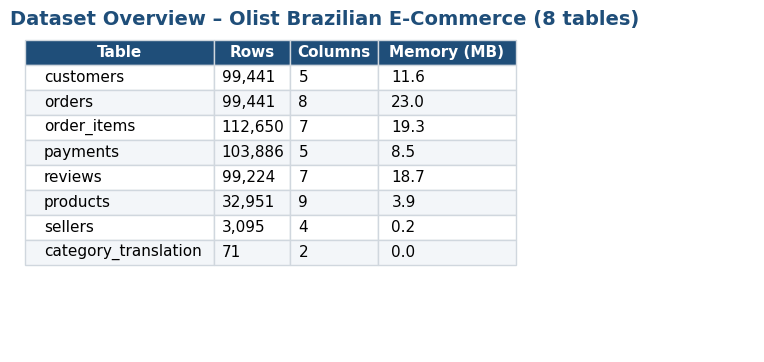

In [37]:
FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}
MEANING = {
    "customers": "One row per customer_id (an order-level customer key) with city and state",
    "orders": "One row per order with status and purchase / delivery timestamps",
    "order_items": "One row per item in an order, with price and freight",
    "payments": "One row per payment record of an order (method, installments, value)",
    "reviews": "Customer review score and comments for an order",
    "products": "Product category and physical attributes",
    "sellers": "Seller city and state",
    "category_translation": "Portuguese to English product category names",
}

raw = {name: pd.read_csv(RAW / file) for name, file in FILES.items()}

overview = pd.DataFrame([
    {
        "Table": name,
        "Rows": f"{len(df):,}",
        "Columns": df.shape[1],
        "Memory (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "Business meaning": MEANING[name],
    }
    for name, df in raw.items()
])
display(overview)
table_to_png(overview[["Table", "Rows", "Columns", "Memory (MB)"]], SHOTS / "dataset-overview.png",
             "Dataset Overview – Olist Brazilian E-Commerce (8 tables)")

### 2.2 Column types: identifier, numeric, categorical, date and text
Each column is classified first, because the type decides how it is cleaned and validated.

In [38]:
ID_COLS = {"order_id", "customer_id", "customer_unique_id", "product_id", "seller_id", "review_id"}
DATE_COLS = {"order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date", "shipping_limit_date",
             "review_creation_date", "review_answer_timestamp"}
NUMERIC_COLS = {"order_item_id", "price", "freight_value", "payment_sequential", "payment_installments",
                "payment_value", "review_score", "product_name_lenght", "product_description_lenght",
                "product_photos_qty", "product_weight_g", "product_length_cm", "product_height_cm",
                "product_width_cm"}
CATEGORICAL_COLS = {"order_status", "payment_type", "product_category_name", "product_category_name_english",
                    "customer_city", "customer_state", "seller_city", "seller_state",
                    "customer_zip_code_prefix", "seller_zip_code_prefix"}
TEXT_COLS = {"review_comment_title", "review_comment_message"}


def column_type(col):
    if col in ID_COLS:
        return "Identifier"
    if col in DATE_COLS:
        return "Date"
    if col in NUMERIC_COLS:
        return "Numeric"
    if col in CATEGORICAL_COLS:
        return "Categorical"
    if col in TEXT_COLS:
        return "Free text"
    return "Other"


column_dictionary = pd.DataFrame([
    {"Table": name, "Column": col, "Type": column_type(col), "Stored as": str(df[col].dtype)}
    for name, df in raw.items() for col in df.columns
])
print("Columns by type:")
display(column_dictionary["Type"].value_counts().rename_axis("Type").to_frame("Columns"))
print("Unclassified columns:", int((column_dictionary["Type"] == "Other").sum()))
print()
print("Date columns are stored as text and must be converted:",
      sorted(column_dictionary.loc[(column_dictionary["Type"] == "Date") & (column_dictionary["Stored as"] != "datetime64[ns]"), "Column"].unique()))
column_dictionary.to_csv(REPORTS / "column_dictionary.csv", index=False)

Columns by type:


,Columns
Type,
Numeric,14
Identifier,12
Categorical,11
Date,8
Free text,2


Unclassified columns: 0

Date columns are stored as text and must be converted: ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_purchase_timestamp', 'review_answer_timestamp', 'review_creation_date', 'shipping_limit_date']


### 2.3 Missing value report
Workflow from the handbook: (1) check nulls column by column, (2) measure the share missing, (3) decide to fill, remove or flag, (4) explain why.

In [39]:
rows = []
for name, df in raw.items():
    for col in df.columns:
        n_missing = int(df[col].isna().sum())
        if n_missing:
            rows.append({"Table": name, "Column": col, "Missing": n_missing,
                         "Missing %": round(n_missing / len(df) * 100, 2)})
missing_report = pd.DataFrame(rows)

# Evidence: why are the order date columns empty?
orders_raw = raw["orders"]
for col in ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]:
    print(col, "->", orders_raw.loc[orders_raw[col].isna(), "order_status"].value_counts().to_dict())

products_raw = raw["products"]
cat_missing_ids = products_raw.loc[products_raw["product_category_name"].isna(), "product_id"]
items_of_cat_missing = int(raw["order_items"]["product_id"].isin(cat_missing_ids).sum())
print()
print(f"Products without category: {len(cat_missing_ids):,} (they are used by {items_of_cat_missing:,} order items)")

order_approved_at -> {'canceled': 141, 'delivered': 14, 'created': 5}
order_delivered_carrier_date -> {'unavailable': 609, 'canceled': 550, 'invoiced': 314, 'processing': 301, 'created': 5, 'approved': 2, 'delivered': 2}
order_delivered_customer_date -> {'shipped': 1107, 'canceled': 619, 'unavailable': 609, 'invoiced': 314, 'processing': 301, 'delivered': 8, 'created': 5, 'approved': 2}

Products without category: 610 (they are used by 1,603 order items)


In [40]:
n_delivered_no_approval = int(((orders_raw["order_status"] == "delivered") & orders_raw["order_approved_at"].isna()).sum())
n_delivered_no_carrier = int(((orders_raw["order_status"] == "delivered") & orders_raw["order_delivered_carrier_date"].isna()).sum())
n_delivered_no_customer_date = int(((orders_raw["order_status"] == "delivered") & orders_raw["order_delivered_customer_date"].isna()).sum())

STRATEGY = {
    "order_approved_at": (
        "Keep missing + flag",
        f"Canceled and newly created orders were never approved, which is a real state. "
        f"{n_delivered_no_approval} delivered orders have a recording gap; an approval time cannot be invented."),
    "order_delivered_carrier_date": (
        "Keep missing + flag",
        f"Orders that are unavailable, canceled, invoiced or still processing have not reached the carrier. "
        f"{n_delivered_no_carrier} delivered orders have a recording gap."),
    "order_delivered_customer_date": (
        "Keep missing + flag",
        f"Shipped, canceled and earlier-stage orders have no delivery yet. {n_delivered_no_customer_date} delivered orders "
        f"without a date are flagged and left out of delivery-time metrics only."),
    "review_comment_title": ("Keep missing", "Customers often skip the comment; the review score is complete and comment text is not analysed."),
    "review_comment_message": ("Keep missing", "Customers often skip the comment; the review score is complete and comment text is not analysed."),
    "product_category_name": (
        "Fill with label 'unknown'",
        f"Categorical field. The same {len(cat_missing_ids):,} products also miss name, description and photo data, so the category "
        f"cannot be recovered. They stay in the data because {items_of_cat_missing:,} order items depend on them."),
    "product_name_lenght": ("Keep missing", "Same products as the missing category; the field is not used in any KPI."),
    "product_description_lenght": ("Keep missing", "Same products as the missing category; the field is not used in any KPI."),
    "product_photos_qty": ("Keep missing", "Same products as the missing category; the field is not used in any KPI."),
    "product_weight_g": ("Fill with median", "Only 2 products; numeric field, so the median is a safe neutral value."),
    "product_length_cm": ("Fill with median", "Only 2 products; numeric field, so the median is a safe neutral value."),
    "product_height_cm": ("Fill with median", "Only 2 products; numeric field, so the median is a safe neutral value."),
    "product_width_cm": ("Fill with median", "Only 2 products; numeric field, so the median is a safe neutral value."),
}
missing_report["Strategy"] = missing_report["Column"].map(lambda c: STRATEGY[c][0])
missing_report["Reason"] = missing_report["Column"].map(lambda c: STRATEGY[c][1])
missing_report.to_csv(REPORTS / "missing_values_report.csv", index=False)
display(missing_report)

,Table,Column,Missing,Missing %,Strategy,Reason
0,orders,order_approved_at,160,0.16,Keep missing + flag,Canceled and newly created orders were never a...
1,orders,order_delivered_carrier_date,1783,1.79,Keep missing + flag,"Orders that are unavailable, canceled, invoice..."
2,orders,order_delivered_customer_date,2965,2.98,Keep missing + flag,"Shipped, canceled and earlier-stage orders hav..."
3,reviews,review_comment_title,87656,88.34,Keep missing,Customers often skip the comment; the review s...
4,reviews,review_comment_message,58247,58.70,Keep missing,Customers often skip the comment; the review s...
5,products,product_category_name,610,1.85,Fill with label 'unknown',Categorical field. The same 610 products also ...
6,products,product_name_lenght,610,1.85,Keep missing,Same products as the missing category; the fie...
7,products,product_description_lenght,610,1.85,Keep missing,Same products as the missing category; the fie...
8,products,product_photos_qty,610,1.85,Keep missing,Same products as the missing category; the fie...
9,products,product_weight_g,2,0.01,Fill with median,"Only 2 products; numeric field, so the median ..."


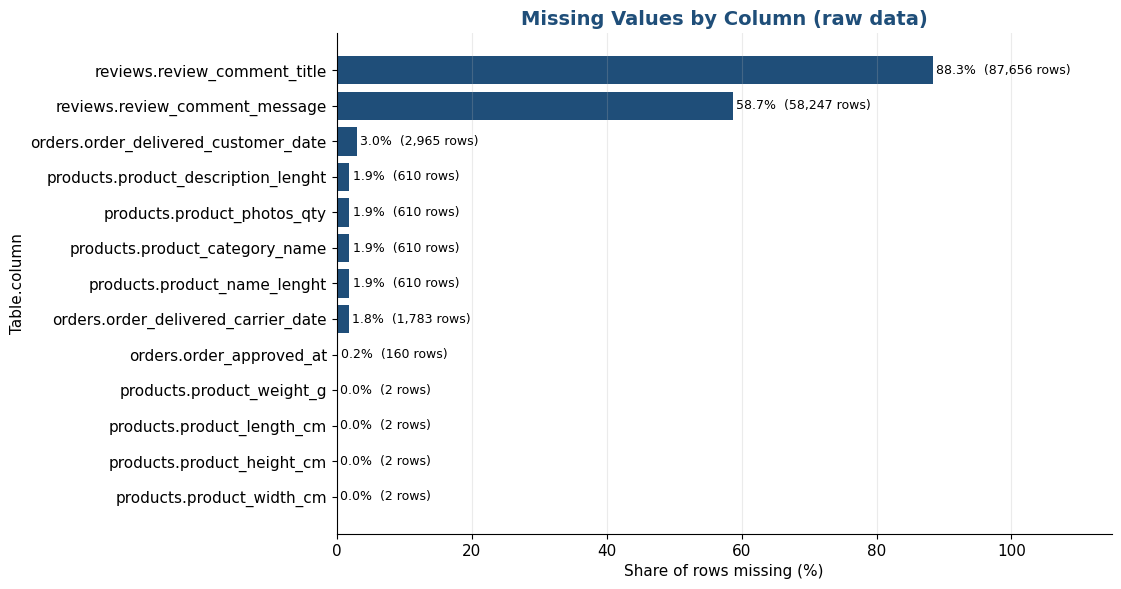

Insight: reviews.review_comment_title has the most gaps (88.3% of rows), mostly review comments customers chose not to write. The order date gaps match order status, so they are expected, not errors.


In [41]:
plot_df = missing_report.assign(label=lambda d: d["Table"] + "." + d["Column"]).sort_values("Missing %")
fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(plot_df["label"], plot_df["Missing %"], color=BLUE)
for bar, pct, n in zip(bars, plot_df["Missing %"], plot_df["Missing"]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f"{pct:.1f}%  ({n:,} rows)", va="center", fontsize=9)
ax.set_xlim(0, plot_df["Missing %"].max() * 1.3)
ax.set_title("Missing Values by Column (raw data)")
ax.set_xlabel("Share of rows missing (%)")
ax.set_ylabel("Table.column")
ax.grid(axis="y", visible=False)
save_chart(fig, "missing-values-report.png", extra_copies=[SHOTS])

top_missing = plot_df.iloc[-1]
print(f"Insight: {top_missing['label']} has the most gaps ({top_missing['Missing %']:.1f}% of rows), "
      "mostly review comments customers chose not to write. The order date gaps match order status, so they are expected, not errors.")

### 2.4 Duplicate analysis
Required steps: detect fully duplicated rows, investigate repeated order IDs, decide whether repeats are valid transactions or accidental copies, and remove only confirmed duplicates.

In [42]:
dup_rows = pd.DataFrame([
    {"Table": name, "Rows": len(df), "Fully duplicated rows": int(df.duplicated().sum())}
    for name, df in raw.items()
])
display(dup_rows)

orders_r, items_r, pay_r, rev_r = raw["orders"], raw["order_items"], raw["payments"], raw["reviews"]
repeat_checks = pd.DataFrame([
    {"Check": "orders: repeated order_id", "Count": int(orders_r["order_id"].duplicated().sum()),
     "Finding": "None. Each order appears once."},
    {"Check": "order_items: repeated (order_id, order_item_id)", "Count": int(items_r.duplicated(["order_id", "order_item_id"]).sum()),
     "Finding": "None. The pair is a unique key."},
    {"Check": "order_items: order_id appearing on more than one row", "Count": int(items_r["order_id"].duplicated().sum()),
     "Finding": "Valid repeats. These are orders with several items."},
    {"Check": "payments: repeated (order_id, payment_sequential)", "Count": int(pay_r.duplicated(["order_id", "payment_sequential"]).sum()),
     "Finding": "None. Several payment rows per order are split payments (for example voucher + card)."},
    {"Check": "reviews: orders with more than one review", "Count": int(rev_r["order_id"].duplicated().sum()),
     "Finding": "Valid. A customer can review the same order again; scores are averaged per order when used."},
    {"Check": "reviews: review_id used on more than one row", "Count": int(rev_r["review_id"].duplicated().sum()),
     "Finding": "The same review_id belongs to different orders; (review_id, order_id) pairs are all unique."},
    {"Check": "reviews: repeated (review_id, order_id)", "Count": int(rev_r.duplicated(["review_id", "order_id"]).sum()),
     "Finding": "None."},
])
display(repeat_checks)
confirmed_duplicates = int(dup_rows["Fully duplicated rows"].sum())
print(f"Confirmed accidental duplicate rows removed: {confirmed_duplicates}")
dup_rows.to_csv(REPORTS / "duplicate_analysis.csv", index=False)
repeat_checks.to_csv(REPORTS / "repeated_id_checks.csv", index=False)

,Table,Rows,Fully duplicated rows
0,customers,99441,0
1,orders,99441,0
2,order_items,112650,0
3,payments,103886,0
4,reviews,99224,0
5,products,32951,0
6,sellers,3095,0
7,category_translation,71,0


,Check,Count,Finding
0,orders: repeated order_id,0,None. Each order appears once.
1,"order_items: repeated (order_id, order_item_id)",0,None. The pair is a unique key.
2,order_items: order_id appearing on more than o...,13984,Valid repeats. These are orders with several i...
3,"payments: repeated (order_id, payment_sequential)",0,None. Several payment rows per order are split...
4,reviews: orders with more than one review,551,Valid. A customer can review the same order ag...
5,reviews: review_id used on more than one row,814,The same review_id belongs to different orders...
6,"reviews: repeated (review_id, order_id)",0,None.


Confirmed accidental duplicate rows removed: 0


### 2.5 Validation checks
Values must be logically consistent. The Olist data has no quantity column; every `order_items` row is one unit and `order_item_id` is only the position of the item in the order.

In [43]:
# Convert text dates to real dates and check that no value was lost in the conversion
orders = raw["orders"].copy()
ORDER_DATES = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"]
nat_before = orders[ORDER_DATES].isna().sum().sum()
for col in ORDER_DATES:
    orders[col] = pd.to_datetime(orders[col], format="%Y-%m-%d %H:%M:%S", errors="coerce")
nat_after = orders[ORDER_DATES].isna().sum().sum()
print(f"Order date values that failed to parse: {int(nat_after - nat_before)}")

items = raw["order_items"].copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
payments = raw["payments"].copy()
reviews = raw["reviews"].copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
products = raw["products"].copy()
customers = raw["customers"].copy()
sellers = raw["sellers"].copy()
translation = raw["category_translation"].copy()

EXPECTED_STATUS = {"delivered", "shipped", "canceled", "unavailable", "invoiced", "processing", "created", "approved"}


def normalize(text):
    return " ".join(str(text).strip().lower().split())


cat_values = products["product_category_name"].dropna().unique()
untranslated = sorted(set(cat_values) - set(translation["product_category_name"]))

checks = []


def add_check(rule, table, violations, action):
    checks.append({"Rule": rule, "Table": table, "Violations": int(violations), "Action": action})


add_check("Price must be greater than 0", "order_items", (items["price"] <= 0).sum(), "None needed")
add_check("Freight value must not be negative", "order_items", (items["freight_value"] < 0).sum(), "None needed")
add_check("Each item row is one unit (order_item_id >= 1)", "order_items", (items["order_item_id"] < 1).sum(), "None needed")
add_check("Payment value must be greater than 0", "payments", (payments["payment_value"] <= 0).sum(),
          "Kept and flagged: zero-value vouchers and 'not_defined' payments carry no money")
add_check("Payment installments must be at least 1", "payments", (payments["payment_installments"] < 1).sum(), "Kept and flagged")
add_check("Review score must be between 1 and 5", "reviews", (~reviews["review_score"].between(1, 5)).sum(), "None needed")
add_check("Order dates follow a valid date format", "orders", nat_after - nat_before, "None needed")
add_check("Order status values are standardized", "orders", (~orders["order_status"].isin(EXPECTED_STATUS)).sum(), "None needed")
add_check("Payment type has a defined value", "payments", (payments["payment_type"] == "not_defined").sum(), "Kept and flagged (value is 0)")
add_check("Category names without spelling variants", "products",
          len(cat_values) - len({normalize(v) for v in cat_values}), "None needed")
add_check("Categories missing an English translation", "products", len(untranslated),
          f"Translated manually: {', '.join(untranslated)}")
add_check("State codes are 2 uppercase letters", "customers", (~customers["customer_state"].str.fullmatch(r"[A-Z]{2}")).sum(), "None needed")
add_check("State codes are 2 uppercase letters", "sellers", (~sellers["seller_state"].str.fullmatch(r"[A-Z]{2}")).sum(), "None needed")
add_check("City names are lowercase without stray spaces", "customers",
          (customers["customer_city"] != customers["customer_city"].map(normalize)).sum(), "None needed")
add_check("Approval time earlier than purchase time", "orders", (orders["order_approved_at"] < orders["order_purchase_timestamp"]).sum(), "None needed")
add_check("Carrier pickup earlier than approval", "orders", (orders["order_delivered_carrier_date"] < orders["order_approved_at"]).sum(),
          "Kept and flagged: timestamps conflict but the order itself is valid")
add_check("Customer delivery earlier than carrier pickup", "orders",
          (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum(), "Kept and flagged")
add_check("Customer delivery earlier than purchase", "orders",
          (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]).sum(), "None needed")
add_check("Delivered order without a delivery date", "orders",
          ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum(),
          "Flagged and excluded from delivery-time metrics")
add_check("Delivery date present but order not delivered", "orders",
          ((orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()).sum(), "Kept; status is the source of truth")
add_check("Order item points to an unknown order", "order_items", (~items["order_id"].isin(orders["order_id"])).sum(), "None needed")
add_check("Order item points to an unknown product", "order_items", (~items["product_id"].isin(products["product_id"])).sum(), "None needed")
add_check("Order item points to an unknown seller", "order_items", (~items["seller_id"].isin(sellers["seller_id"])).sum(), "None needed")
add_check("Order points to an unknown customer", "orders", (~orders["customer_id"].isin(customers["customer_id"])).sum(), "None needed")
add_check("Payment points to an unknown order", "payments", (~payments["order_id"].isin(orders["order_id"])).sum(), "None needed")
add_check("Review points to an unknown order", "reviews", (~reviews["order_id"].isin(orders["order_id"])).sum(), "None needed")
orders_without_items = int((~orders["order_id"].isin(items["order_id"])).sum())
add_check("Order has no item rows", "orders", orders_without_items,
          "Kept in order counts; excluded from revenue because there is no price")

validation_report = pd.DataFrame(checks)
validation_report["Result"] = np.where(validation_report["Violations"] == 0, "PASS", "REVIEWED")
display(validation_report)
validation_report.to_csv(REPORTS / "validation_checks.csv", index=False)
print(f"{(validation_report['Result'] == 'PASS').sum()} of {len(validation_report)} checks passed with zero violations; "
      f"the others are documented in the cleaning decisions below.")

Order date values that failed to parse: 0


,Rule,Table,Violations,Action,Result
0,Price must be greater than 0,order_items,0,None needed,PASS
1,Freight value must not be negative,order_items,0,None needed,PASS
2,Each item row is one unit (order_item_id >= 1),order_items,0,None needed,PASS
3,Payment value must be greater than 0,payments,9,Kept and flagged: zero-value vouchers and 'not...,REVIEWED
4,Payment installments must be at least 1,payments,2,Kept and flagged,REVIEWED
5,Review score must be between 1 and 5,reviews,0,None needed,PASS
6,Order dates follow a valid date format,orders,0,None needed,PASS
7,Order status values are standardized,orders,0,None needed,PASS
8,Payment type has a defined value,payments,3,Kept and flagged (value is 0),REVIEWED
9,Category names without spelling variants,products,0,None needed,PASS


18 of 27 checks passed with zero violations; the others are documented in the cleaning decisions below.


In [44]:
print("Orders without items, by status:")
print(orders.loc[~orders["order_id"].isin(items["order_id"]), "order_status"].value_counts().to_dict())
print()
print("Zero-value payments, by type:")
print(payments.loc[payments["payment_value"] <= 0, "payment_type"].value_counts().to_dict())
print("Order status of those payments:",
      orders.loc[orders["order_id"].isin(payments.loc[payments["payment_value"] <= 0, "order_id"]), "order_status"].value_counts().to_dict())

Orders without items, by status:
{'unavailable': 603, 'canceled': 164, 'created': 5, 'invoiced': 2, 'shipped': 1}

Zero-value payments, by type:
{'voucher': 6, 'not_defined': 3}
Order status of those payments: {'delivered': 4, 'canceled': 3, 'shipped': 1}


### 2.6 Apply the cleaning and save the cleaned datasets

In [45]:
# ---- customers and sellers: consistent text, zip codes with leading zeros
customers["customer_city"] = customers["customer_city"].map(normalize)
customers["customer_state"] = customers["customer_state"].str.strip().str.upper()
customers["customer_zip_code_prefix"] = customers["customer_zip_code_prefix"].astype(str).str.zfill(5)
sellers["seller_city"] = sellers["seller_city"].map(normalize)
sellers["seller_state"] = sellers["seller_state"].str.strip().str.upper()
sellers["seller_zip_code_prefix"] = sellers["seller_zip_code_prefix"].astype(str).str.zfill(5)

# ---- orders: flags instead of deleting rows
orders["flag_delivered_without_date"] = (orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()
orders["flag_date_sequence_issue"] = (
    (orders["order_delivered_carrier_date"] < orders["order_approved_at"])
    | (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"])
)

# ---- products: consistent column names, category fill, English names, median for dimensions
products = products.rename(columns={"product_name_lenght": "product_name_length",
                                    "product_description_lenght": "product_description_length"})
products["product_category_name"] = products["product_category_name"].fillna("unknown")
category_map = dict(zip(translation["product_category_name"], translation["product_category_name_english"]))
category_map.update({
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_preparers",
    "unknown": "unknown",
})
products["product_category_english"] = products["product_category_name"].map(category_map)
for col in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products[col] = products[col].fillna(products[col].median())

# ---- payments: flag, never delete
payments["flag_zero_value"] = payments["payment_value"] <= 0

# ---- reviews: drop the two free-text columns (not analysed, mostly empty, large)
reviews = reviews.drop(columns=["review_comment_title", "review_comment_message"])

cleaned = {
    "customers": customers, "orders": orders, "order_items": items, "payments": payments,
    "reviews": reviews, "products": products, "sellers": sellers,
}
for name, df in cleaned.items():
    df.to_csv(CLEAN / f"{name}_cleaned.csv", index=False)

print("Products still missing a category after cleaning:", int((products["product_category_name"] == "unknown").sum()), "(labelled 'unknown')")
print("Products without an English name:", int(products["product_category_english"].isna().sum()))
print("Flagged orders - delivered without date:", int(orders["flag_delivered_without_date"].sum()),
      "| date sequence issue:", int(orders["flag_date_sequence_issue"].sum()))
print("Raw files untouched:", all((RAW / f).exists() for f in FILES.values()))

Products still missing a category after cleaning: 610 (labelled 'unknown')
Products without an English name: 0
Flagged orders - delivered without date: 8 | date sequence issue: 1382
Raw files untouched: True


In [46]:
n_seq = int(orders["flag_date_sequence_issue"].sum())
decisions = pd.DataFrame([
    {"Issue": "Date columns stored as text", "Evidence": "8 date columns across 3 tables",
     "Decision": "Converted to datetime", "Why": "Needed for monthly trends and delivery time; 0 values failed to parse"},
    {"Issue": "Missing order timestamps", "Evidence": "160 / 1,783 / 2,965 gaps in approval / carrier / customer delivery",
     "Decision": "Kept as missing", "Why": "Gaps follow order status (canceled, shipped, unavailable); filling would invent dates"},
    {"Issue": "Delivered orders without a delivery date", "Evidence": f"{n_delivered_no_customer_date} orders",
     "Decision": "Flagged, excluded from delivery-time metrics only", "Why": "They still count as completed sales"},
    {"Issue": "Conflicting delivery timestamps", "Evidence": f"{n_seq} orders where pickup precedes approval or delivery precedes pickup",
     "Decision": "Flagged, kept", "Why": "Order value and status are valid; deleting would remove real sales"},
    {"Issue": "Products without category", "Evidence": f"{len(cat_missing_ids):,} products, {items_of_cat_missing:,} order items",
     "Decision": "Labelled 'unknown'", "Why": "Deleting them would remove revenue and bias category results"},
    {"Issue": "Two categories missing English names", "Evidence": ", ".join(untranslated),
     "Decision": "Translated manually", "Why": "Avoids Portuguese labels in charts"},
    {"Issue": "Misspelled column names", "Evidence": "product_name_lenght, product_description_lenght",
     "Decision": "Renamed to *_length", "Why": "Consistent column names"},
    {"Issue": "Zero-value payments", "Evidence": f"{int(payments['flag_zero_value'].sum())} rows (vouchers and 'not_defined')",
     "Decision": "Flagged, kept", "Why": "Valid zero-cost vouchers; no effect on price-based revenue"},
    {"Issue": "Duplicate rows", "Evidence": f"{confirmed_duplicates} fully duplicated rows in all 8 tables",
     "Decision": "Nothing removed", "Why": "Repeated IDs are valid multi-item orders or split payments"},
    {"Issue": "Orders without item rows", "Evidence": f"{orders_without_items} orders (mostly unavailable / canceled)",
     "Decision": "Kept in the orders table", "Why": "No price exists, so they add no revenue"},
    {"Issue": "Zip codes lost leading zeros", "Evidence": "Stored as integers",
     "Decision": "Padded to 5 characters", "Why": "Zip prefixes are identifiers, not numbers"},
    {"Issue": "Review comment text", "Evidence": "Large and mostly empty",
     "Decision": "Dropped from the cleaned reviews file only", "Why": "Not analysed; the raw file keeps the text"},
])
decisions.to_csv(REPORTS / "cleaning_decisions.csv", index=False)
display(decisions)
METRICS["cleaning_decisions"] = decisions.to_dict("records")
METRICS["validation_checks"] = len(validation_report)
METRICS["validation_passed"] = int((validation_report["Result"] == "PASS").sum())

,Issue,Evidence,Decision,Why
0,Date columns stored as text,8 date columns across 3 tables,Converted to datetime,Needed for monthly trends and delivery time; 0...
1,Missing order timestamps,"160 / 1,783 / 2,965 gaps in approval / carrier...",Kept as missing,"Gaps follow order status (canceled, shipped, u..."
2,Delivered orders without a delivery date,8 orders,"Flagged, excluded from delivery-time metrics only",They still count as completed sales
3,Conflicting delivery timestamps,1382 orders where pickup precedes approval or ...,"Flagged, kept",Order value and status are valid; deleting wou...
4,Products without category,"610 products, 1,603 order items",Labelled 'unknown',Deleting them would remove revenue and bias ca...
5,Two categories missing English names,"pc_gamer, portateis_cozinha_e_preparadores_de_...",Translated manually,Avoids Portuguese labels in charts
6,Misspelled column names,"product_name_lenght, product_description_lenght",Renamed to *_length,Consistent column names
7,Zero-value payments,9 rows (vouchers and 'not_defined'),"Flagged, kept",Valid zero-cost vouchers; no effect on price-b...
8,Duplicate rows,0 fully duplicated rows in all 8 tables,Nothing removed,Repeated IDs are valid multi-item orders or sp...
9,Orders without item rows,775 orders (mostly unavailable / canceled),Kept in the orders table,"No price exists, so they add no revenue"


### 2.7 Build the sales dataset used for analysis

In [47]:
final_sales = (
    items.merge(orders[["order_id", "customer_id", "order_status", "order_purchase_timestamp",
                        "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id", how="left")
    .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]], on="customer_id", how="left")
    .merge(products[["product_id", "product_category_english"]], on="product_id", how="left")
    .rename(columns={"product_category_english": "category"})
)
final_sales["order_month"] = final_sales["order_purchase_timestamp"].dt.to_period("M").astype(str)
final_sales = final_sales[["order_id", "order_item_id", "product_id", "customer_unique_id", "category",
                           "price", "freight_value", "order_status", "order_month", "order_purchase_timestamp",
                           "customer_city", "customer_state"]]
final_sales.to_csv(CLEAN / "final_sales_dataset.csv", index=False)

print("final_sales_dataset:", final_sales.shape, "- one row per sold item")
print("Rows lost in merges:", len(items) - len(final_sales), "| missing category:", int(final_sales["category"].isna().sum()))
display(final_sales.head())

final_sales_dataset: (112650, 12) - one row per sold item
Rows lost in merges: 0 | missing category: 0


,order_id,order_item_id,product_id,customer_unique_id,category,price,freight_value,order_status,order_month,order_purchase_timestamp,customer_city,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,871766c5855e863f6eccc05f988b23cb,cool_stuff,58.90,13.29,delivered,2017-09,2017-09-13 08:59:02,campos dos goytacazes,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,eb28e67c4c0b83846050ddfb8a35d051,pet_shop,239.90,19.93,delivered,2017-04,2017-04-26 10:53:06,santa fe do sul,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,3818d81c6709e39d06b2738a8d3a2474,furniture_decor,199.00,17.87,delivered,2018-01,2018-01-14 14:33:31,para de minas,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,af861d436cfc08b2c2ddefd0ba074622,perfumery,12.99,12.79,delivered,2018-08,2018-08-08 10:00:35,atibaia,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,64b576fb70d441e8f1b2d7d446e483c5,garden_tools,199.90,18.14,delivered,2017-02,2017-02-04 13:57:51,varzea paulista,SP


---
## Task 2 – Sales Data Analysis

**Definitions used throughout (so every number can be checked):**
- A *completed sale* is an item in an order with status `delivered`.
- *Revenue* is the sum of item `price` for completed sales. Freight is excluded.
- *Units* are item rows (one row = one unit).
- A *repeat customer* has more than one delivered order under the same `customer_unique_id`.

### 3.1 KPI summary

,KPI,Value,Meaning
0,Total Revenue,"R$13,221,498.11",Total value of all completed (delivered) sales...
1,Total Orders,"96,478",Number of delivered orders
2,Average Order Value,R$137.04,Revenue divided by total orders
3,Total Units Sold,"110,197",Sum of items sold in delivered orders
4,Top-Selling Category,"bed_bath_table (10,953 units)",Category with the most units sold
5,Top Revenue Category,"health_beauty (R$1,233,132)",Category with the highest sales contribution
6,Top Revenue-Generating Product,"bb50f2e236... (health_beauty, R$63,560)",Product with the highest revenue (Olist hides ...
7,Revenue Realization,97.3%,Delivered product value as a share of the valu...


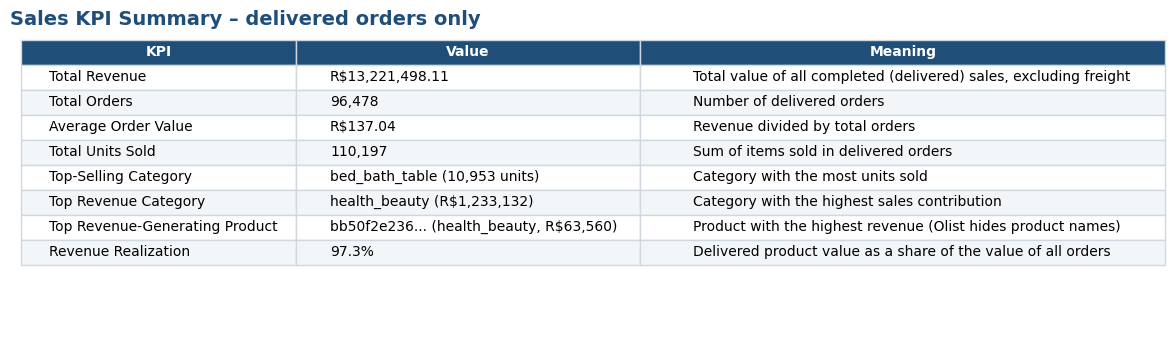

In [48]:
delivered = final_sales[final_sales["order_status"] == "delivered"].copy()

total_revenue = delivered["price"].sum()
total_orders = delivered["order_id"].nunique()
aov = total_revenue / total_orders
total_units = len(delivered)

cat_revenue = delivered.groupby("category")["price"].sum().sort_values(ascending=False)
cat_units = delivered.groupby("category").size().sort_values(ascending=False)
product_perf = (delivered.groupby(["product_id", "category"])
                .agg(revenue=("price", "sum"), units=("order_item_id", "size"), orders=("order_id", "nunique"))
                .reset_index())
best_product = product_perf.sort_values("revenue", ascending=False).iloc[0]
top_units_product = product_perf.sort_values("units", ascending=False).iloc[0]

all_status_value = final_sales["price"].sum()
realization = total_revenue / all_status_value * 100

kpi_table = pd.DataFrame([
    ("Total Revenue", f"R${total_revenue:,.2f}", "Total value of all completed (delivered) sales, excluding freight"),
    ("Total Orders", f"{total_orders:,}", "Number of delivered orders"),
    ("Average Order Value", f"R${aov:,.2f}", "Revenue divided by total orders"),
    ("Total Units Sold", f"{total_units:,}", "Sum of items sold in delivered orders"),
    ("Top-Selling Category", f"{cat_units.index[0]} ({cat_units.iloc[0]:,} units)", "Category with the most units sold"),
    ("Top Revenue Category", f"{cat_revenue.index[0]} (R${cat_revenue.iloc[0]:,.0f})", "Category with the highest sales contribution"),
    ("Top Revenue-Generating Product", f"{best_product['product_id'][:10]}... ({best_product['category']}, R${best_product['revenue']:,.0f})",
     "Product with the highest revenue (Olist hides product names)"),
    ("Revenue Realization", f"{realization:.1f}%", "Delivered product value as a share of the value of all orders"),
], columns=["KPI", "Value", "Meaning"])
display(kpi_table)
kpi_table.to_csv(REPORTS / "kpi_summary.csv", index=False)
table_to_png(kpi_table, SHOTS / "sales-kpi-summary.png", "Sales KPI Summary – delivered orders only", font=10)

In [49]:
# Double-check the KPI formulas with an independent calculation straight from the raw files
raw_delivered_ids = raw["orders"].loc[raw["orders"]["order_status"] == "delivered", "order_id"]
raw_items = raw["order_items"][raw["order_items"]["order_id"].isin(raw_delivered_ids)]
assert abs(raw_items["price"].sum() - total_revenue) < 0.01, "Revenue mismatch"
assert raw_items["order_id"].nunique() == total_orders, "Order count mismatch"
assert len(raw_items) == total_units, "Unit count mismatch"
assert abs(aov - raw_items["price"].sum() / raw_items["order_id"].nunique()) < 1e-9, "AOV mismatch"

# Reconcile with what customers actually paid (price + freight + installment interest)
paid = raw["payments"].loc[raw["payments"]["order_id"].isin(raw_delivered_ids), "payment_value"].sum()
freight = raw_items["freight_value"].sum()
print("KPI formulas verified against the raw files.")
print(f"Payments received (delivered orders): R${paid:,.2f}")
print(f"Product value + freight:               R${total_revenue + freight:,.2f}")
print(f"Difference: {abs(paid - total_revenue - freight) / paid * 100:.2f}% (interest on installments and rounding)")

METRICS.update({
    "total_revenue": float(total_revenue), "total_orders": int(total_orders), "aov": float(aov),
    "total_units": int(total_units), "top_units_category": cat_units.index[0], "top_units_category_units": int(cat_units.iloc[0]),
    "top_revenue_category": cat_revenue.index[0], "top_revenue_category_value": float(cat_revenue.iloc[0]),
    "best_product_id": best_product["product_id"], "best_product_category": best_product["category"],
    "best_product_revenue": float(best_product["revenue"]), "best_product_units": int(best_product["units"]),
    "realization_pct": float(realization), "all_status_value": float(all_status_value),
    "kpi_table": kpi_table.to_dict("records"),
})

KPI formulas verified against the raw files.
Payments received (delivered orders): R$15,422,461.77
Product value + freight:               R$15,419,773.75
Difference: 0.02% (interest on installments and rounding)


### 3.2 Trend analysis
Sep–Dec 2016 and Sep–Oct 2018 contain only a handful of orders (the dataset starts and ends there), so trend statistics use the complete months January 2017 to August 2018.

In [50]:
orders_per_month = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()
print("All orders per month (shows why 2016 and Sep-Oct 2018 are excluded from trends):")
print(orders_per_month.to_string())

START, END = pd.Period("2017-01"), pd.Period("2018-08")
delivered["month"] = delivered["order_purchase_timestamp"].dt.to_period("M")
monthly = (delivered.groupby("month")
           .agg(revenue=("price", "sum"), orders=("order_id", "nunique"), units=("order_item_id", "size"))
           .reset_index())
monthly = monthly[(monthly["month"] >= START) & (monthly["month"] <= END)].reset_index(drop=True)
monthly["revenue_growth_pct"] = monthly["revenue"].pct_change() * 100
monthly["label"] = monthly["month"].dt.strftime("%b %Y")
display(monthly.assign(month=monthly["label"]).drop(columns="label").round(1))
monthly.assign(month=monthly["label"]).drop(columns="label").to_csv(REPORTS / "monthly_sales_trend.csv", index=False)

All orders per month (shows why 2016 and Sep-Oct 2018 are excluded from trends):
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


,month,revenue,orders,units,revenue_growth_pct
0,Jan 2017,111798.4,750,913,NaN
1,Feb 2017,234223.4,1653,1858,109.5
2,Mar 2017,359198.8,2546,2897,53.4
3,Apr 2017,340669.7,2303,2569,-5.2
4,May 2017,489338.2,3546,4004,43.6
5,Jun 2017,421923.4,3135,3489,-13.8
6,Jul 2017,481604.5,3872,4416,14.1
7,Aug 2017,554699.7,4193,4797,15.2
8,Sep 2017,607399.7,4150,4737,9.5
9,Oct 2017,648247.6,4478,5214,6.7


In [51]:
peak = monthly.loc[monthly["revenue"].idxmax()]
prev = monthly.loc[monthly["revenue"].idxmax() - 1]
first, last = monthly.iloc[0], monthly.iloc[-1]
growth_total = (last["revenue"] / first["revenue"] - 1) * 100
dec_after_peak = monthly.loc[monthly["label"] == "Dec 2017", "revenue"].iloc[0]
drop_after_peak = (dec_after_peak / peak["revenue"] - 1) * 100

# Evidence for the peak: look at single days, not just months
daily_orders = orders.groupby(orders["order_purchase_timestamp"].dt.date).size()
bf_day = date(2017, 11, 24)
nov_days = daily_orders[[d for d in daily_orders.index if d.year == 2017 and d.month == 11 and d != bf_day]]
bf_orders = int(daily_orders[bf_day])
nov_typical = float(nov_days.median())
print(f"Peak month: {peak['label']} with R${peak['revenue']:,.0f} ({peak['revenue_growth_pct']:+.1f}% vs {prev['label']})")
print(f"Jan 2017 -> Aug 2018 revenue growth: {growth_total:+.0f}%")
print(f"Dec 2017 revenue vs the peak: {drop_after_peak:+.1f}%")
print(f"Orders on 24 Nov 2017: {bf_orders:,} vs a typical November day of {nov_typical:,.0f} ({bf_orders / nov_typical:.1f}x)")

METRICS.update({
    "peak_month": peak["label"], "peak_revenue": float(peak["revenue"]), "peak_growth_pct": float(peak["revenue_growth_pct"]),
    "prev_month": prev["label"], "first_month": first["label"], "first_revenue": float(first["revenue"]),
    "last_month": last["label"], "last_revenue": float(last["revenue"]), "growth_total_pct": float(growth_total),
    "drop_after_peak_pct": float(drop_after_peak), "bf_orders": bf_orders, "nov_typical_orders": nov_typical,
    "monthly": monthly.assign(month=monthly["label"]).drop(columns="label").to_dict("records"),
})

Peak month: Nov 2017 with R$987,765 (+52.4% vs Oct 2017)
Jan 2017 -> Aug 2018 revenue growth: +650%
Dec 2017 revenue vs the peak: -26.5%
Orders on 24 Nov 2017: 1,176 vs a typical November day of 192 (6.1x)


In [52]:
# Category performance over time: top 5 categories by revenue
top5 = cat_revenue.head(5).index.tolist()
cat_month = (delivered[delivered["category"].isin(top5)]
             .groupby(["month", "category"])["price"].sum().unstack("category").fillna(0))
cat_month = cat_month[(cat_month.index >= START) & (cat_month.index <= END)][top5]

h1 = cat_month.loc[pd.Period("2017-01"):pd.Period("2017-08")].sum()
h2 = cat_month.loc[pd.Period("2018-01"):pd.Period("2018-08")].sum()
cat_growth = ((h2 / h1 - 1) * 100).sort_values(ascending=False)
print("Revenue growth, Jan-Aug 2018 vs Jan-Aug 2017, top 5 categories:")
print(cat_growth.round(1).to_string())
METRICS["cat_growth"] = {k: float(v) for k, v in cat_growth.items()}
METRICS["fastest_cat"], METRICS["fastest_cat_growth"] = cat_growth.index[0], float(cat_growth.iloc[0])
METRICS["slowest_cat"], METRICS["slowest_cat_growth"] = cat_growth.index[-1], float(cat_growth.iloc[-1])

Revenue growth, Jan-Aug 2018 vs Jan-Aug 2017, top 5 categories:
category
watches_gifts            242.0
health_beauty            210.3
sports_leisure           138.6
computers_accessories    131.2
bed_bath_table           109.2


### 3.3 Region analysis

In [53]:
state_revenue = delivered.groupby("customer_state")["price"].sum().sort_values(ascending=False)
top_state, top_state_share = state_revenue.index[0], state_revenue.iloc[0] / state_revenue.sum() * 100
top3_share = state_revenue.head(3).sum() / state_revenue.sum() * 100

city_orders = delivered.groupby("customer_city")["order_id"].nunique().sort_values(ascending=False)
top_city, top_city_share = city_orders.index[0], city_orders.iloc[0] / total_orders * 100
top10_city_share = city_orders.head(10).sum() / total_orders * 100

# Are high-value orders concentrated in certain cities?
order_value = (delivered.groupby("order_id")
               .agg(order_value=("price", "sum"), city=("customer_city", "first")).reset_index())
threshold = order_value["order_value"].quantile(0.90)
order_value["high_value"] = order_value["order_value"] >= threshold
city_hv = order_value.groupby("city").agg(all_orders=("order_id", "size"), high_orders=("high_value", "sum"))
city_hv["share_all_pct"] = city_hv["all_orders"] / city_hv["all_orders"].sum() * 100
city_hv["share_high_pct"] = city_hv["high_orders"] / city_hv["high_orders"].sum() * 100
city_hv["concentration_index"] = city_hv["share_high_pct"] / city_hv["share_all_pct"]
big_cities = city_hv[city_hv["all_orders"] >= 500].sort_values("high_orders", ascending=False).head(6)
display(big_cities.round(2))

print(f"Top state by revenue: {top_state} ({top_state_share:.1f}%); top 3 states: {top3_share:.1f}%")
print(f"Top city by orders: {top_city} ({top_city_share:.1f}% of orders); top 10 cities: {top10_city_share:.1f}%")
print(f"High-value order threshold (top 10% of orders): R${threshold:,.2f}")
METRICS.update({
    "top_state": top_state, "top_state_share": float(top_state_share), "top3_state_share": float(top3_share),
    "top_city": top_city, "top_city_share": float(top_city_share), "top10_city_share": float(top10_city_share),
    "hv_threshold": float(threshold),
    "hv_top_city": big_cities.index[0], "hv_top_city_index": float(big_cities["concentration_index"].iloc[0]),
    "hv_top_city_share_high": float(big_cities["share_high_pct"].iloc[0]),
    "hv_top_city_share_all": float(big_cities["share_all_pct"].iloc[0]),
})

,all_orders,high_orders,share_all_pct,share_high_pct,concentration_index
city,,,,,
sao paulo,15045,1313,15.59,13.50,0.87
rio de janeiro,6601,697,6.84,7.17,1.05
belo horizonte,2697,237,2.80,2.44,0.87
brasilia,2071,217,2.15,2.23,1.04
curitiba,1489,160,1.54,1.65,1.07
porto alegre,1342,144,1.39,1.48,1.06


Top state by revenue: SP (38.3%); top 3 states: 63.4%
Top city by orders: sao paulo (15.6% of orders); top 10 cities: 35.1%
High-value order threshold (top 10% of orders): R$269.00


### 3.4 Customer insights

In [54]:
cust = pd.DataFrame({
    "orders": delivered.groupby("customer_unique_id")["order_id"].nunique(),
    "revenue": delivered.groupby("customer_unique_id")["price"].sum(),
})
cust["segment"] = np.where(cust["orders"] > 1, "Repeat", "One-time")

segments = (cust.groupby("segment")
            .agg(customers=("orders", "size"), revenue=("revenue", "sum"), avg_orders=("orders", "mean"))
            .assign(customer_share_pct=lambda d: d["customers"] / d["customers"].sum() * 100,
                    revenue_share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100,
                    revenue_per_customer=lambda d: d["revenue"] / d["customers"]))
display(segments.round(2))

freq = pd.cut(cust["orders"], bins=[0, 1, 2, 100], labels=["1 order", "2 orders", "3+ orders"]).value_counts().sort_index()
print("Customers by number of delivered orders:", {k: int(v) for k, v in freq.items()})

repeat_customers = int(segments.loc["Repeat", "customers"])
unique_customers = len(cust)
repeat_pct = segments.loc["Repeat", "customer_share_pct"]
repeat_rev_share = segments.loc["Repeat", "revenue_share_pct"]
rev_per_repeat = segments.loc["Repeat", "revenue_per_customer"]
rev_per_onetime = segments.loc["One-time", "revenue_per_customer"]

# Is purchase behaviour evenly distributed or skewed?
sorted_rev = cust["revenue"].sort_values(ascending=False)
top10_cust_share = sorted_rev.head(int(len(sorted_rev) * 0.10)).sum() / sorted_rev.sum() * 100
print(f"Unique customers: {unique_customers:,} | repeat: {repeat_customers:,} ({repeat_pct:.2f}%) | repeat revenue share: {repeat_rev_share:.2f}%")
print(f"Revenue per customer: repeat R${rev_per_repeat:,.2f} vs one-time R${rev_per_onetime:,.2f}")
print(f"Top 10% of customers generate {top10_cust_share:.1f}% of revenue")

,customers,revenue,avg_orders,customer_share_pct,revenue_share_pct,revenue_per_customer
segment,,,,,,
One-time,90557,12493089.36,1.00,97.0,94.49,137.96
Repeat,2801,728408.75,2.11,3.0,5.51,260.05


Customers by number of delivered orders: {'1 order': 90557, '2 orders': 2573, '3+ orders': 228}
Unique customers: 93,358 | repeat: 2,801 (3.00%) | repeat revenue share: 5.51%
Revenue per customer: repeat R$260.05 vs one-time R$137.96
Top 10% of customers generate 41.1% of revenue


In [55]:
# Are some categories preferred by specific customer groups (repeat vs one-time)?
seg_sales = delivered.merge(cust["segment"], left_on="customer_unique_id", right_index=True)
mix = seg_sales.pivot_table(index="category", columns="segment", values="price", aggfunc="sum").fillna(0)
mix = mix / mix.sum() * 100
mix["difference_pp"] = mix["Repeat"] - mix["One-time"]
relevant = mix[mix[["Repeat", "One-time"]].max(axis=1) >= 2].sort_values("difference_pp")
display(relevant.round(2).tail(3))
display(relevant.round(2).head(3))

# Repeat rate by state (states with at least 1,000 customers)
state_cust = delivered.drop_duplicates("customer_unique_id").groupby("customer_state").size()
cust_state = delivered.drop_duplicates("customer_unique_id").set_index("customer_unique_id")["customer_state"]
state_repeat = (cust.join(cust_state).assign(is_repeat=lambda d: d["orders"] > 1)
                .groupby("customer_state")["is_repeat"].mean() * 100)
state_repeat = state_repeat[state_cust[state_cust >= 1000].index].sort_values(ascending=False)
print("Repeat-customer rate by state (states with 1,000+ customers):")
print(state_repeat.round(2).to_string())

over, under = relevant.index[-1], relevant.index[0]
METRICS.update({
    "unique_customers": int(unique_customers), "repeat_customers": repeat_customers, "repeat_pct": float(repeat_pct),
    "repeat_rev_share": float(repeat_rev_share), "rev_per_repeat": float(rev_per_repeat), "rev_per_onetime": float(rev_per_onetime),
    "top10_cust_share": float(top10_cust_share),
    "over_cat": over, "over_cat_pp": float(relevant["difference_pp"].iloc[-1]),
    "under_cat": under, "under_cat_pp": float(relevant["difference_pp"].iloc[0]),
    "best_repeat_state": state_repeat.index[0], "best_repeat_state_pct": float(state_repeat.iloc[0]),
    "worst_repeat_state": state_repeat.index[-1], "worst_repeat_state_pct": float(state_repeat.iloc[-1]),
})

segment,One-time,Repeat,difference_pp
category,,,
sports_leisure,7.07,9.78,2.71
furniture_decor,5.20,8.53,3.33
bed_bath_table,7.43,13.02,5.59


segment,One-time,Repeat,difference_pp
category,,,
health_beauty,9.43,7.48,-1.96
cool_stuff,4.71,2.93,-1.78
watches_gifts,8.92,7.17,-1.75


Repeat-customer rate by state (states with 1,000+ customers):
customer_state
RJ    3.28
SP    3.12
RS    3.04
GO    3.01
DF    2.97
MG    2.95
PR    2.94
ES    2.91
BA    2.82
SC    2.67
PE    2.20
CE    1.67


### 3.5 Delivery performance and revenue realization

In [56]:
deliv = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()].copy()
deliv["delivery_days"] = (deliv["order_delivered_customer_date"] - deliv["order_purchase_timestamp"]).dt.total_seconds() / 86400
deliv["is_late"] = deliv["order_delivered_customer_date"] > deliv["order_estimated_delivery_date"]
deliv = deliv.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
assert deliv["delivery_days"].min() > 0, "Negative delivery time found"

avg_days, median_days = deliv["delivery_days"].mean(), deliv["delivery_days"].median()
late_pct = deliv["is_late"].mean() * 100
by_state = (deliv.groupby("customer_state")
            .agg(orders=("order_id", "size"), late_pct=("is_late", lambda s: s.mean() * 100), avg_days=("delivery_days", "mean"))
            .query("orders >= 500").sort_values("late_pct", ascending=False))
worst_state, worst_late = by_state.index[0], by_state["late_pct"].iloc[0]
best_state, best_late = by_state.index[-1], by_state["late_pct"].iloc[-1]

# Does lateness hurt customer satisfaction?
review_per_order = reviews.groupby("order_id")["review_score"].mean()
deliv["review_score"] = deliv["order_id"].map(review_per_order)
score_late = deliv.loc[deliv["is_late"], "review_score"].mean()
score_ontime = deliv.loc[~deliv["is_late"], "review_score"].mean()

# Revenue realization by order status
status_table = (final_sales.groupby("order_status")
                .agg(orders=("order_id", "nunique"), product_value=("price", "sum"))
                .sort_values("product_value", ascending=False))
status_table["value_share_pct"] = status_table["product_value"] / status_table["product_value"].sum() * 100
display(status_table.round(2))
lost_value = status_table.loc[status_table.index.isin(["canceled", "unavailable"]), "product_value"].sum()
cancel_pct = orders["order_status"].isin(["canceled", "unavailable"]).mean() * 100

print(f"Average delivery time: {avg_days:.1f} days (median {median_days:.1f}) | late deliveries: {late_pct:.2f}% of {len(deliv):,}")
print(f"Highest late rate (states with 500+ orders): {worst_state} {worst_late:.1f}% | lowest: {best_state} {best_late:.1f}%")
print(f"Average review score: on time {score_ontime:.2f} vs late {score_late:.2f}")
print(f"Canceled or unavailable orders: {cancel_pct:.2f}% of all orders, product value R${lost_value:,.0f}")
METRICS.update({
    "avg_delivery_days": float(avg_days), "median_delivery_days": float(median_days), "late_pct": float(late_pct),
    "worst_late_state": worst_state, "worst_late_pct": float(worst_late), "best_late_state": best_state, "best_late_pct": float(best_late),
    "score_late": float(score_late), "score_ontime": float(score_ontime), "cancel_pct": float(cancel_pct),
    "lost_value": float(lost_value), "status_counts": orders["order_status"].value_counts().to_dict(),
})

,orders,product_value,value_share_pct
order_status,,,
delivered,96478,13221498.11,97.28
shipped,1106,150727.44,1.11
canceled,461,95235.27,0.70
invoiced,312,61526.37,0.45
processing,301,60439.22,0.44
unavailable,6,2007.69,0.01
approved,2,209.60,0.00


Average delivery time: 12.6 days (median 10.2) | late deliveries: 8.11% of 96,470
Highest late rate (states with 500+ orders): MA 19.7% | lowest: PR 5.0%
Average review score: on time 4.29 vs late 2.57
Canceled or unavailable orders: 1.24% of all orders, product value R$97,243


### 3.6 Payment behaviour

In [57]:
delivered_ids = set(delivered["order_id"])
pay_delivered = payments[payments["order_id"].isin(delivered_ids)]
pay_share = pay_delivered.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)
pay_share = pay_share[pay_share > 0]
pay_share_pct = pay_share / pay_share.sum() * 100
card = pay_delivered[pay_delivered["payment_type"] == "credit_card"]
avg_installments = card["payment_installments"].mean()
multi_installment_pct = (card["payment_installments"] > 1).mean() * 100
display(pay_share_pct.round(2).to_frame("Share of payment value (%)"))
print(f"Credit card payments: average {avg_installments:.1f} installments; {multi_installment_pct:.1f}% are paid in 2 or more installments")
METRICS.update({
    "pay_share": {k: float(v) for k, v in pay_share_pct.items()}, "top_payment": pay_share_pct.index[0],
    "top_payment_pct": float(pay_share_pct.iloc[0]), "avg_installments": float(avg_installments),
    "multi_installment_pct": float(multi_installment_pct),
})

,Share of payment value (%)
payment_type,
credit_card,78.46
boleto,17.96
voucher,2.22
debit_card,1.35


Credit card payments: average 3.5 installments; 66.8% are paid in 2 or more installments


---
## Task 3 – Visualization Challenge
Every chart has a title, labelled axes, one colour system and a short written finding. Required types: bar, line, pie and one dashboard mockup.

### 4.1 Bar charts

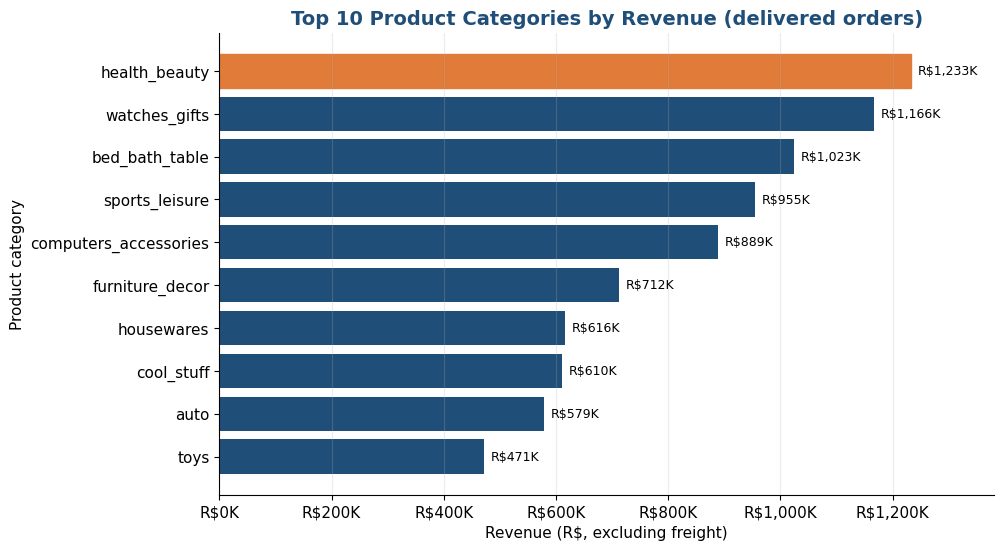

Insight: health_beauty earns the most (R$1,233,132). The top 10 categories together provide 62.4% of revenue, so a small set of categories drives results.


In [58]:
# Bar 1 - revenue by category
top10 = cat_revenue.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10.index, top10.values, color=BLUE)
bars[-1].set_color(ORANGE)
for bar in bars:
    ax.text(bar.get_width() + top10.max() * 0.01, bar.get_y() + bar.get_height() / 2, money_k(bar.get_width()), va="center", fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(money_k))
ax.set_xlim(0, top10.max() * 1.12)
ax.set_title("Top 10 Product Categories by Revenue (delivered orders)")
ax.set_xlabel("Revenue (R$, excluding freight)")
ax.set_ylabel("Product category")
ax.grid(axis="y", visible=False)
save_chart(fig, "revenue-by-category.png")
top10_share = cat_revenue.head(10).sum() / cat_revenue.sum() * 100
CAPTIONS["revenue-by-category"] = (
    f"{cat_revenue.index[0]} earns the most (R${cat_revenue.iloc[0]:,.0f}). The top 10 categories together provide "
    f"{top10_share:.1f}% of revenue, so a small set of categories drives results.")
print("Insight:", CAPTIONS["revenue-by-category"])
METRICS["top10_cat_share"] = float(top10_share)

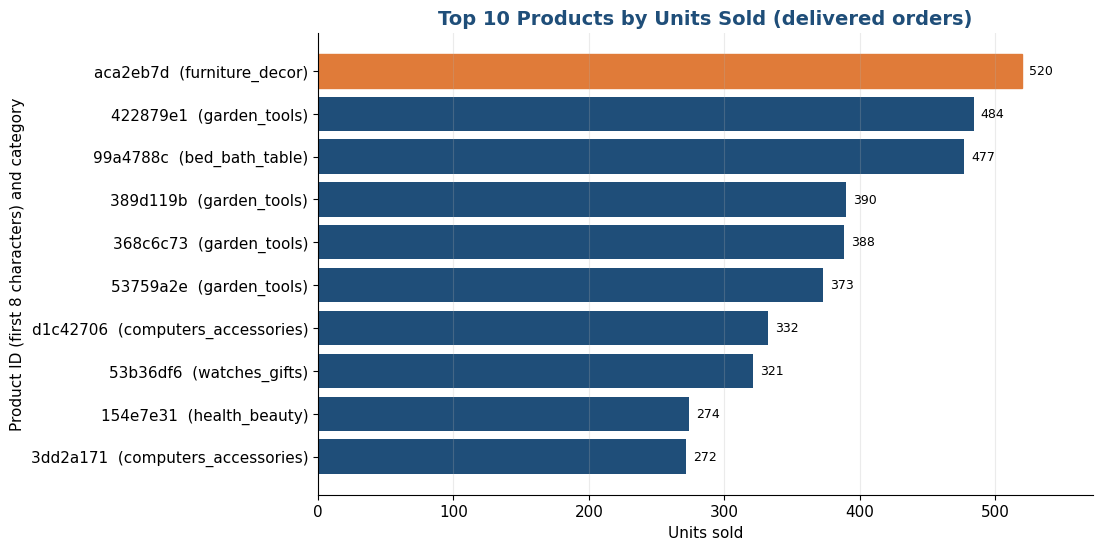

Insight: The best-selling product (furniture_decor) sold 520 units. 8 of these 10 products cost less than the average item price (R$120), and together they are only 3.5% of all units, so volume is spread across many products rather than a few hits.


In [59]:
# Bar 2 - top 10 products by units sold
top_prod = product_perf.sort_values("units", ascending=False).head(10).sort_values("units")
labels = [f"{pid[:8]}  ({cat})" for pid, cat in zip(top_prod["product_id"], top_prod["category"])]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, top_prod["units"], color=BLUE)
bars[-1].set_color(ORANGE)
for bar in bars:
    ax.text(bar.get_width() + top_prod["units"].max() * 0.01, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width()):,}", va="center", fontsize=9)
ax.set_xlim(0, top_prod["units"].max() * 1.1)
ax.set_title("Top 10 Products by Units Sold (delivered orders)")
ax.set_xlabel("Units sold")
ax.set_ylabel("Product ID (first 8 characters) and category")
ax.grid(axis="y", visible=False)
save_chart(fig, "top-10-products-by-units.png")
avg_item_price = delivered["price"].mean()
top_prod_avg_price = top_prod["revenue"] / top_prod["units"]
n_cheaper = int((top_prod_avg_price < avg_item_price).sum())
top10_units_share = top_prod["units"].sum() / total_units * 100
CAPTIONS["top-10-products-by-units"] = (
    f"The best-selling product ({top_units_product['category']}) sold {int(top_units_product['units']):,} units. "
    f"{n_cheaper} of these 10 products cost less than the average item price (R${avg_item_price:,.0f}), and together they are only "
    f"{top10_units_share:.1f}% of all units, so volume is spread across many products rather than a few hits.")
print("Insight:", CAPTIONS["top-10-products-by-units"])
METRICS["top10_units_share"] = float(top10_units_share)
METRICS["top10_cheaper_than_avg"] = n_cheaper
METRICS["avg_item_price"] = float(avg_item_price)
METRICS["top_units_product_units"] = int(top_units_product["units"])
METRICS["top_units_product_category"] = top_units_product["category"]

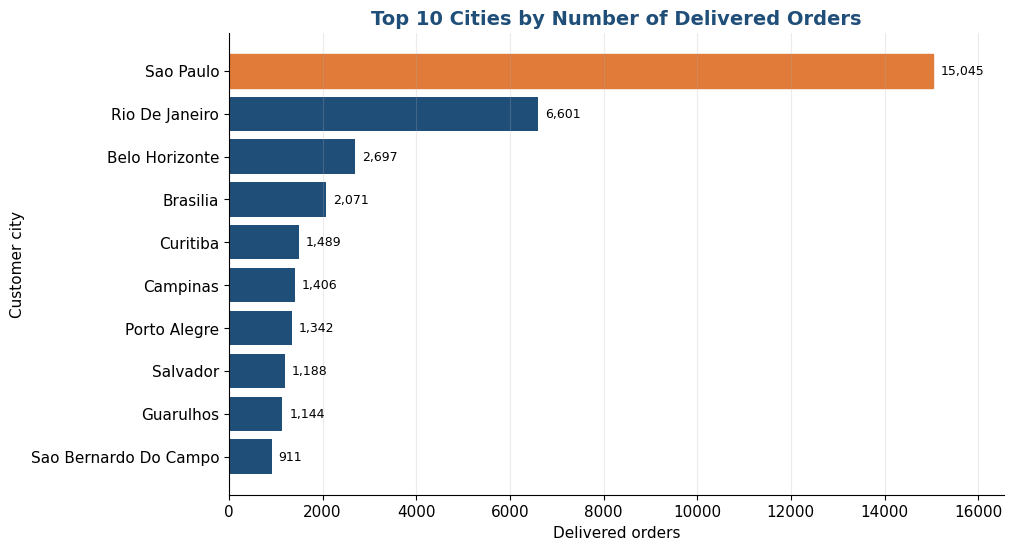

Insight: Sao Paulo alone accounts for 15.6% of delivered orders and the top 10 cities for 35.1%, so order density is highly concentrated in a few large cities.


In [60]:
# Bar 3 - orders by city
top_cities = city_orders.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh([c.title() for c in top_cities.index], top_cities.values, color=BLUE)
bars[-1].set_color(ORANGE)
for bar in bars:
    ax.text(bar.get_width() + top_cities.max() * 0.01, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width()):,}", va="center", fontsize=9)
ax.set_xlim(0, top_cities.max() * 1.1)
ax.set_title("Top 10 Cities by Number of Delivered Orders")
ax.set_xlabel("Delivered orders")
ax.set_ylabel("Customer city")
ax.grid(axis="y", visible=False)
save_chart(fig, "orders-by-city.png")
CAPTIONS["orders-by-city"] = (
    f"{top_city.title()} alone accounts for {top_city_share:.1f}% of delivered orders and the top 10 cities for {top10_city_share:.1f}%, "
    "so order density is highly concentrated in a few large cities.")
print("Insight:", CAPTIONS["orders-by-city"])

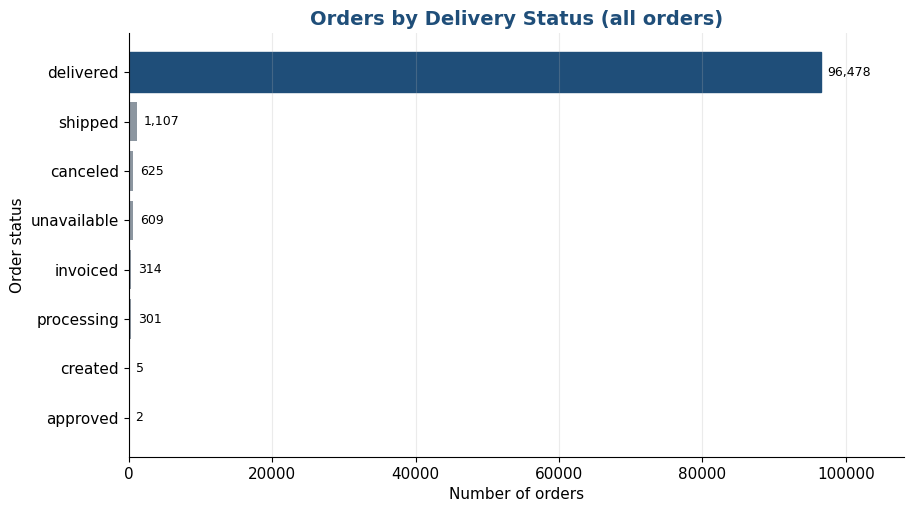

Insight: 97.0% of orders reach the delivered status. Canceled and unavailable orders together are 1.24% of orders (R$97,243 of product value that never became revenue).


In [61]:
# Bar 4 - delivery status counts (all orders)
status_counts = orders["order_status"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(status_counts.index, status_counts.values, color=GREY)
bars[-1].set_color(BLUE)
for bar in bars:
    ax.text(bar.get_width() + status_counts.max() * 0.01, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width()):,}", va="center", fontsize=9)
ax.set_xlim(0, status_counts.max() * 1.12)
ax.set_title("Orders by Delivery Status (all orders)")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Order status")
ax.grid(axis="y", visible=False)
save_chart(fig, "delivery-status-counts.png")
delivered_share = status_counts["delivered"] / status_counts.sum() * 100
CAPTIONS["delivery-status-counts"] = (
    f"{delivered_share:.1f}% of orders reach the delivered status. Canceled and unavailable orders together are {cancel_pct:.2f}% "
    f"of orders (R${lost_value:,.0f} of product value that never became revenue).")
print("Insight:", CAPTIONS["delivery-status-counts"])
METRICS["delivered_share"] = float(delivered_share)

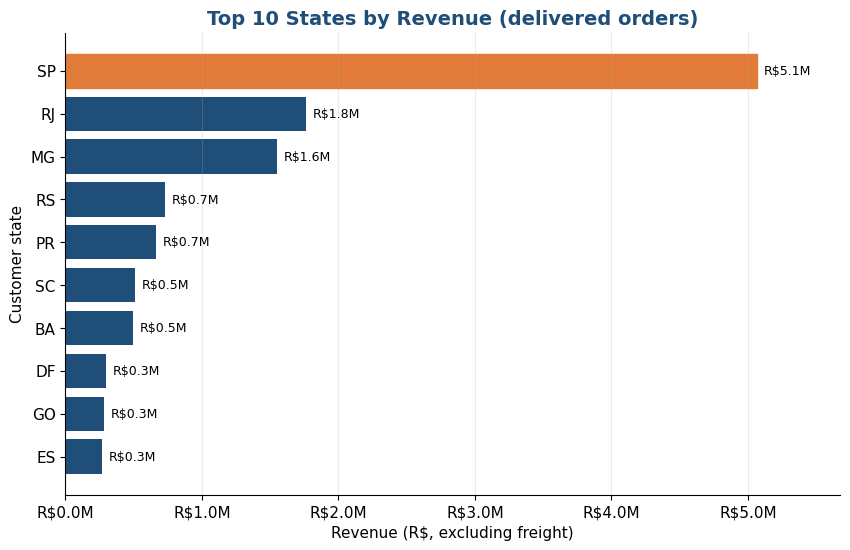

Insight: SP contributes 38.3% of revenue and the top three states 63.4%, so service quality in these states has the largest effect on overall results.


In [62]:
# Bar 5 - revenue by state
top_states = state_revenue.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_states.index, top_states.values, color=BLUE)
bars[-1].set_color(ORANGE)
for bar in bars:
    ax.text(bar.get_width() + top_states.max() * 0.01, bar.get_y() + bar.get_height() / 2, money_m(bar.get_width()), va="center", fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(money_m))
ax.set_xlim(0, top_states.max() * 1.12)
ax.set_title("Top 10 States by Revenue (delivered orders)")
ax.set_xlabel("Revenue (R$, excluding freight)")
ax.set_ylabel("Customer state")
ax.grid(axis="y", visible=False)
save_chart(fig, "revenue-by-state.png")
CAPTIONS["revenue-by-state"] = (
    f"{top_state} contributes {top_state_share:.1f}% of revenue and the top three states {top3_share:.1f}%, "
    "so service quality in these states has the largest effect on overall results.")
print("Insight:", CAPTIONS["revenue-by-state"])

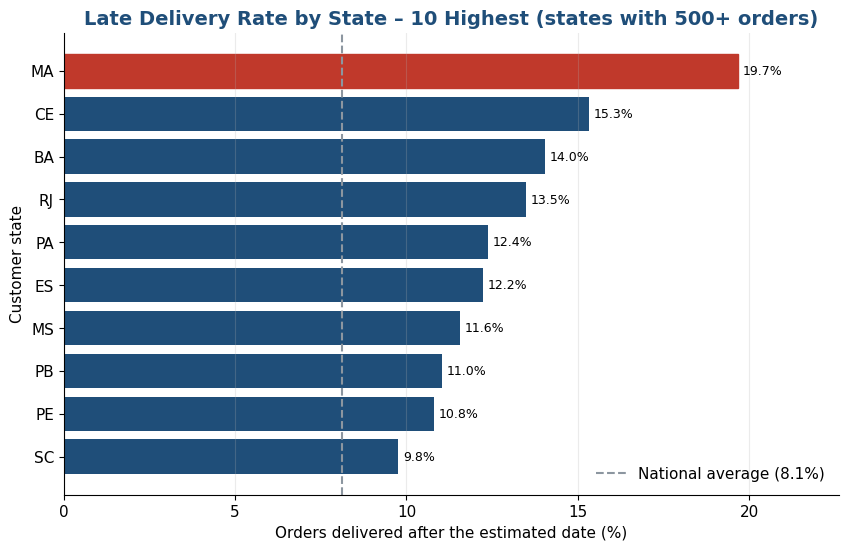

Insight: MA has the highest late rate (19.7% versus 8.1% nationally). Late orders average a review score of 2.57 compared with 4.29 for on-time orders, which suggests lateness is linked to unhappy customers.


In [63]:
# Bar 6 - late delivery rate by state (worst 10 of the states with 500+ orders)
worst10 = by_state.head(10).sort_values("late_pct")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(worst10.index, worst10["late_pct"], color=BLUE)
bars[-1].set_color(RED)
ax.axvline(late_pct, color=GREY, linestyle="--", linewidth=1.5, label=f"National average ({late_pct:.1f}%)")
ax.legend(loc="lower right", frameon=False)
for bar in bars:
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.1f}%", va="center", fontsize=9)
ax.set_xlim(0, worst10["late_pct"].max() * 1.15)
ax.set_title("Late Delivery Rate by State – 10 Highest (states with 500+ orders)")
ax.set_xlabel("Orders delivered after the estimated date (%)")
ax.set_ylabel("Customer state")
ax.grid(axis="y", visible=False)
save_chart(fig, "late-delivery-by-state.png")
CAPTIONS["late-delivery-by-state"] = (
    f"{worst_state} has the highest late rate ({worst_late:.1f}% versus {late_pct:.1f}% nationally). Late orders average a review score of "
    f"{score_late:.2f} compared with {score_ontime:.2f} for on-time orders, which suggests lateness is linked to unhappy customers.")
print("Insight:", CAPTIONS["late-delivery-by-state"])

### 4.2 Line charts

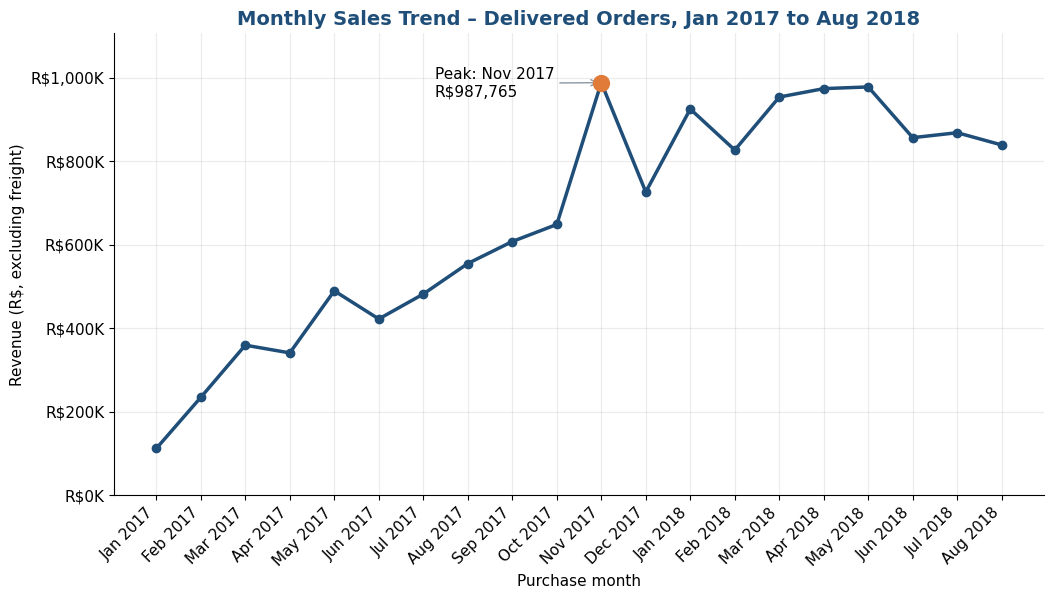

Insight: Revenue grew from R$111,798 in Jan 2017 to R$838,577 in Aug 2018. Nov 2017 is the peak (+52% on Oct 2017), and 1,176 orders on 24 Nov 2017 alone (6.1x a typical November day) point to a promotion such as Black Friday as the likely driver. Revenue then fell 26% in December, so the jump was a spike, not a new baseline.


In [64]:
# Line 1 - monthly revenue with the peak annotated
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(monthly))
ax.plot(x, monthly["revenue"], marker="o", linewidth=2.5, color=BLUE)
peak_i = int(monthly["revenue"].idxmax())
ax.scatter([peak_i], [peak["revenue"]], s=130, color=ORANGE, zorder=5)
ax.annotate(f"Peak: {peak['label']}\nR${peak['revenue']:,.0f}", xy=(peak_i, peak["revenue"]),
            xytext=(-120, -10), textcoords="offset points", arrowprops={"arrowstyle": "->", "color": GREY}, fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(monthly["label"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(money_k))
ax.set_ylim(0, monthly["revenue"].max() * 1.12)
ax.set_title("Monthly Sales Trend – Delivered Orders, Jan 2017 to Aug 2018")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Revenue (R$, excluding freight)")
save_chart(fig, "monthly-sales-trend.png", extra_copies=[SHOTS])
CAPTIONS["monthly-sales-trend"] = (
    f"Revenue grew from R${first['revenue']:,.0f} in {first['label']} to R${last['revenue']:,.0f} in {last['label']}. "
    f"{peak['label']} is the peak ({peak['revenue_growth_pct']:+.0f}% on {prev['label']}), and {bf_orders:,} orders on 24 Nov 2017 alone "
    f"({bf_orders / nov_typical:.1f}x a typical November day) point to a promotion such as Black Friday as the likely driver. "
    f"Revenue then fell {abs(drop_after_peak):.0f}% in December, so the jump was a spike, not a new baseline.")
print("Insight:", CAPTIONS["monthly-sales-trend"])

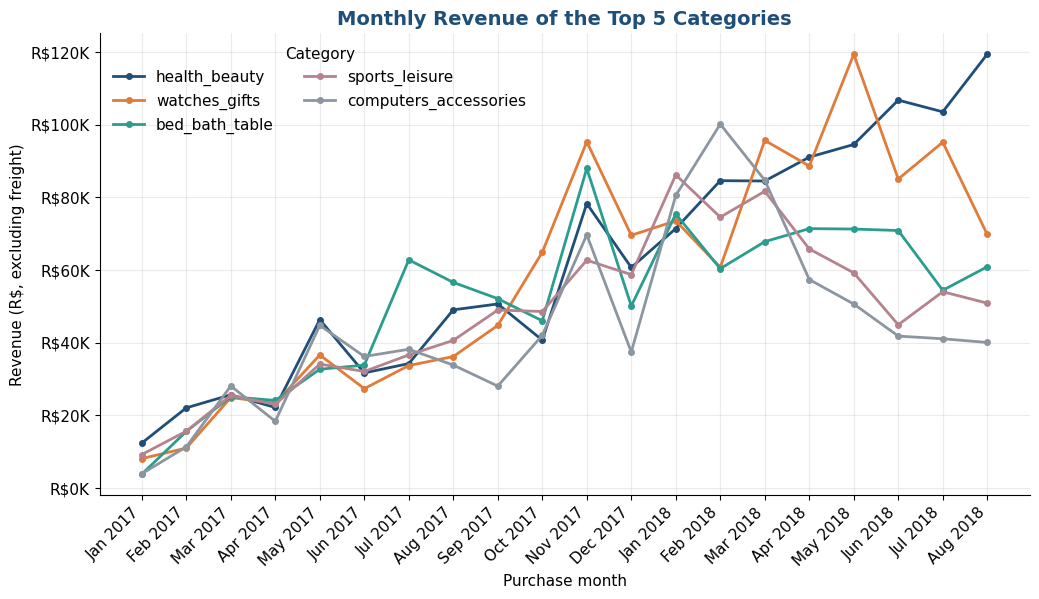

Insight: Between Jan-Aug 2017 and Jan-Aug 2018, watches_gifts grew fastest (+242%) while bed_bath_table grew slowest (+109%), so category growth is uneven.


In [65]:
# Line 2 - revenue trend of the top 5 categories
fig, ax = plt.subplots(figsize=(12, 6))
line_colors = [BLUE, ORANGE, TEAL, "#B5838D", GREY]
x = np.arange(len(cat_month))
for color, cat in zip(line_colors, top5):
    ax.plot(x, cat_month[cat], marker="o", markersize=4, linewidth=2, color=color, label=cat)
ax.set_xticks(x)
ax.set_xticklabels([p.strftime("%b %Y") for p in cat_month.index], rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(money_k))
ax.set_title("Monthly Revenue of the Top 5 Categories")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Revenue (R$, excluding freight)")
ax.legend(title="Category", frameon=False, ncol=2)
save_chart(fig, "category-revenue-trend.png")
CAPTIONS["category-revenue-trend"] = (
    f"Between Jan-Aug 2017 and Jan-Aug 2018, {METRICS['fastest_cat']} grew fastest ({METRICS['fastest_cat_growth']:+.0f}%) while "
    f"{METRICS['slowest_cat']} grew slowest ({METRICS['slowest_cat_growth']:+.0f}%), so category growth is uneven.")
print("Insight:", CAPTIONS["category-revenue-trend"])

### 4.3 Pie chart

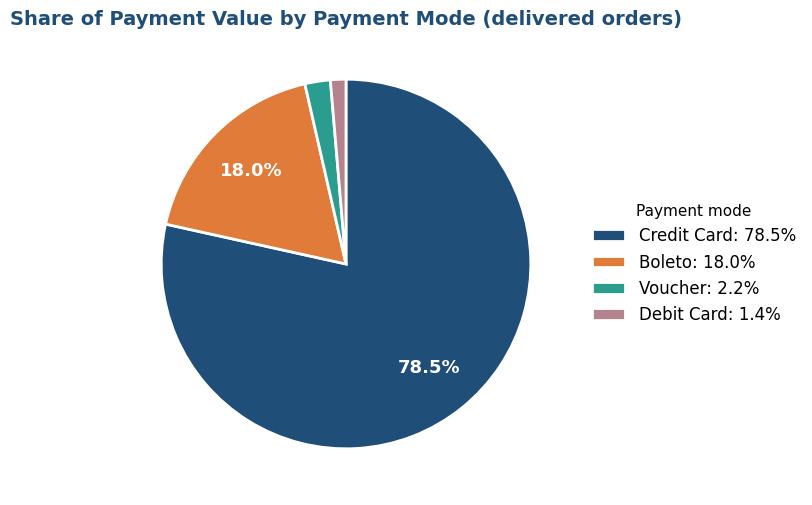

Insight: Credit Card accounts for 78.5% of payment value, and 67% of card payments are split into installments, so installment-friendly checkout matters to customers.


In [66]:
# Pie - sales contribution by payment mode (only 4 segments, so a pie is readable)
fig, ax = plt.subplots(figsize=(9, 6))
labels = [t.replace("_", " ").title() for t in pay_share_pct.index]
wedges, texts, autotexts = ax.pie(
    pay_share_pct.values, colors=PIE_COLORS[:len(pay_share_pct)], startangle=90, counterclock=False,
    autopct=lambda p: f"{p:.1f}%" if p >= 5 else "", pctdistance=0.72,
    wedgeprops={"edgecolor": "white", "linewidth": 2})
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(13)
# Legend carries every value, so the small slices stay readable
ax.legend(wedges, [f"{lab}: {val:.1f}%" for lab, val in zip(labels, pay_share_pct.values)],
          title="Payment mode", loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=12)
ax.set_title("Share of Payment Value by Payment Mode (delivered orders)")
ax.grid(False)
save_chart(fig, "payment-mode-share.png")
CAPTIONS["payment-mode-share"] = (
    f"{pay_share_pct.index[0].replace('_', ' ').title()} accounts for {pay_share_pct.iloc[0]:.1f}% of payment value, and "
    f"{multi_installment_pct:.0f}% of card payments are split into installments, so installment-friendly checkout matters to customers.")
print("Insight:", CAPTIONS["payment-mode-share"])

### 4.4 Dashboard mockup

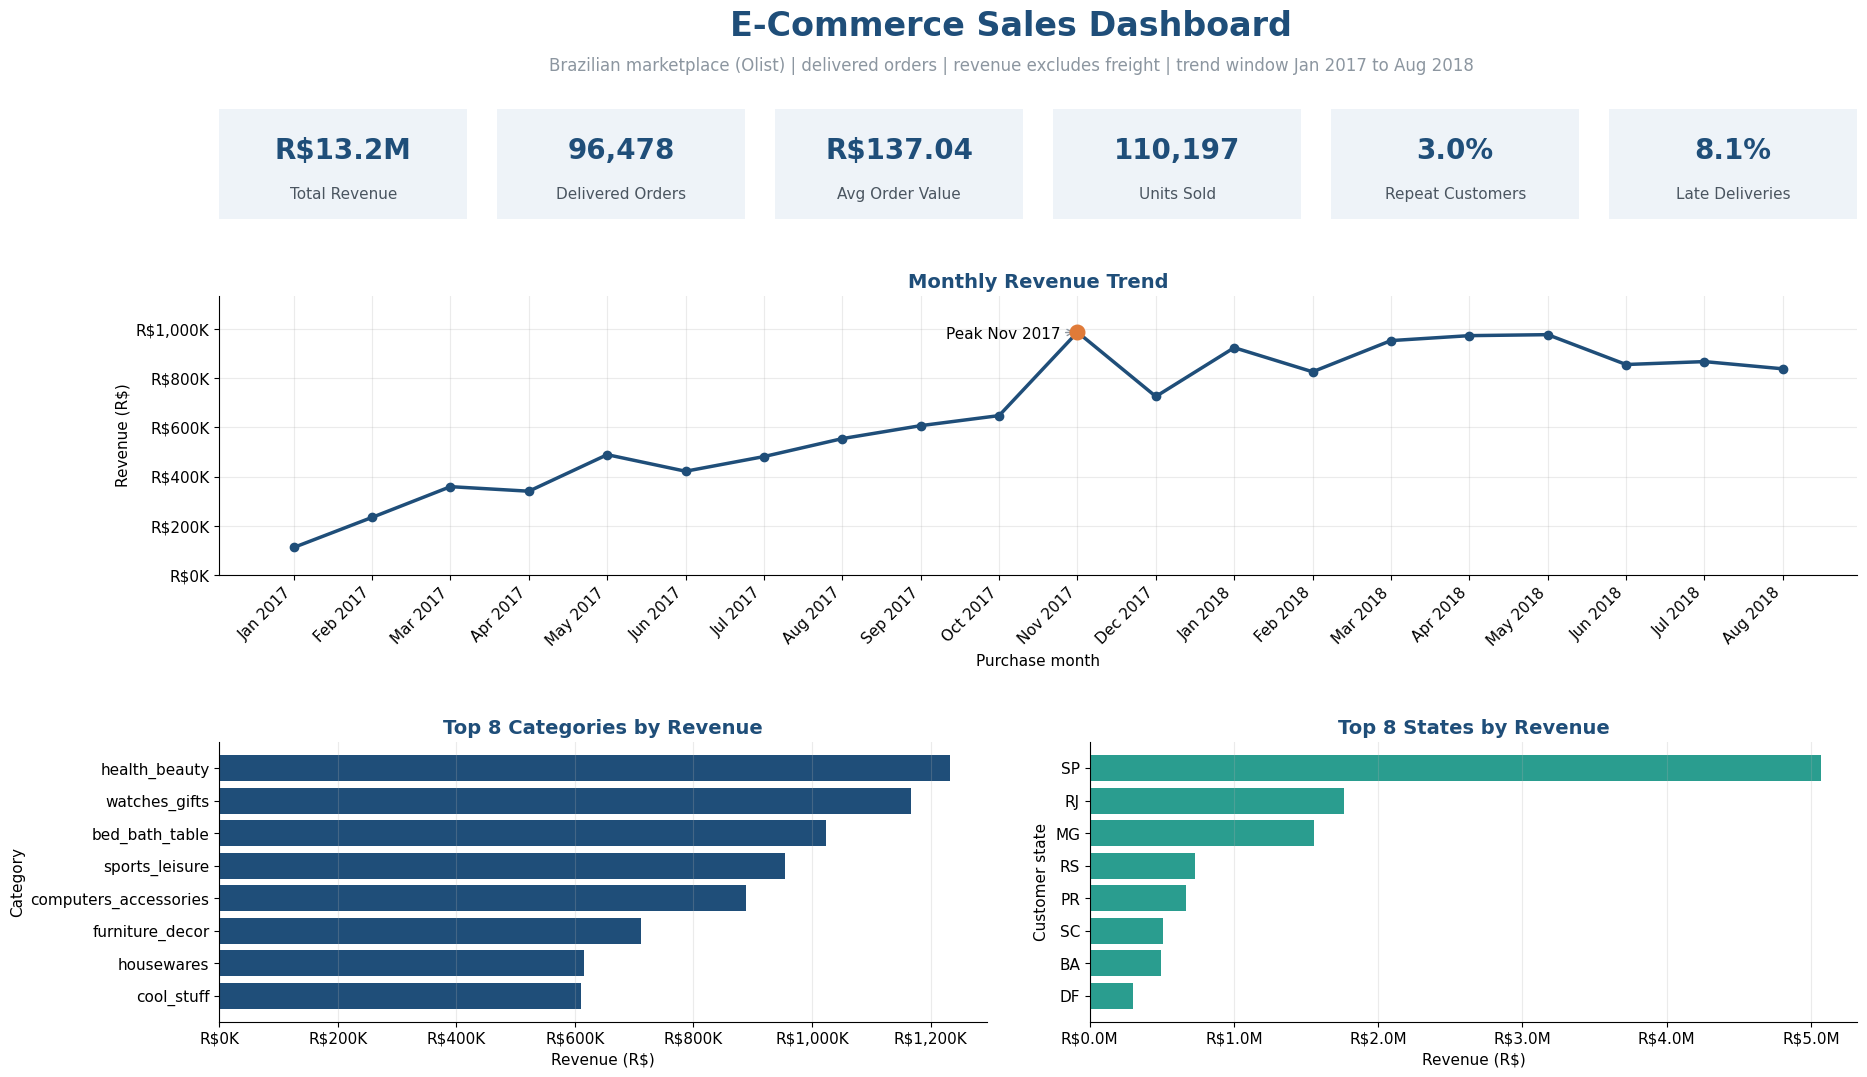

Insight: One page combines six KPIs, the monthly trend, category and regional comparisons: SP and health_beauty lead, and Nov 2017 stands out as the peak month.


In [67]:
cards = [
    ("Total Revenue", money_m(total_revenue)),
    ("Delivered Orders", f"{total_orders:,}"),
    ("Avg Order Value", f"R${aov:,.2f}"),
    ("Units Sold", f"{total_units:,}"),
    ("Repeat Customers", f"{repeat_pct:.1f}%"),
    ("Late Deliveries", f"{late_pct:.1f}%"),
]
fig = plt.figure(figsize=(18, 11))
fig.suptitle("E-Commerce Sales Dashboard", fontsize=24, fontweight="bold", color=BLUE, y=0.99)
fig.text(0.5, 0.935, "Brazilian marketplace (Olist) | delivered orders | revenue excludes freight | trend window Jan 2017 to Aug 2018",
         ha="center", fontsize=12, color=GREY)
card_grid = fig.add_gridspec(1, 6, wspace=0.12, left=0.06, right=0.97, top=0.9, bottom=0.8)
grid = fig.add_gridspec(2, 6, height_ratios=[2.0, 2.0], hspace=0.6, wspace=0.55, left=0.06, right=0.97, top=0.73, bottom=0.07)

for i, (label, value) in enumerate(cards):
    ax = fig.add_subplot(card_grid[0, i])
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#EEF3F8"))
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=20, fontweight="bold", color=BLUE, transform=ax.transAxes)
    ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=11, color="#4A5560", transform=ax.transAxes)
    ax.axis("off")

ax = fig.add_subplot(grid[0, :])
x = np.arange(len(monthly))
ax.plot(x, monthly["revenue"], marker="o", linewidth=2.5, color=BLUE)
ax.scatter([peak_i], [peak["revenue"]], s=110, color=ORANGE, zorder=5)
ax.annotate(f"Peak {peak['label']}", xy=(peak_i, peak["revenue"]), xytext=(-95, -5), textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": GREY}, fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(monthly["label"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(money_k))
ax.set_ylim(0, monthly["revenue"].max() * 1.15)
ax.set_title("Monthly Revenue Trend")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Revenue (R$)")

ax = fig.add_subplot(grid[1, 0:3])
c8 = cat_revenue.head(8).sort_values()
ax.barh(c8.index, c8.values, color=BLUE)
ax.xaxis.set_major_formatter(FuncFormatter(money_k))
ax.set_title("Top 8 Categories by Revenue")
ax.set_xlabel("Revenue (R$)")
ax.set_ylabel("Category")
ax.grid(axis="y", visible=False)

ax = fig.add_subplot(grid[1, 3:6])
s8 = state_revenue.head(8).sort_values()
ax.barh(s8.index, s8.values, color=TEAL)
ax.xaxis.set_major_formatter(FuncFormatter(money_m))
ax.set_title("Top 8 States by Revenue")
ax.set_xlabel("Revenue (R$)")
ax.set_ylabel("Customer state")
ax.grid(axis="y", visible=False)

save_chart(fig, "dashboard-mockup.png", folder=DASH, extra_copies=[SHOTS])
CAPTIONS["dashboard-mockup"] = (
    f"One page combines six KPIs, the monthly trend, category and regional comparisons: {top_state} and {cat_revenue.index[0]} lead, "
    f"and {peak['label']} stands out as the peak month.")
print("Insight:", CAPTIONS["dashboard-mockup"])

---
## Key Findings, Recommendations and Limitations
Findings are observations backed by the numbers above. Recommendations are separate suggested actions, and every recommendation points to the finding behind it.

In [68]:
findings = [
    ("Overall performance",
     f"Delivered orders generated R${total_revenue:,.0f} from {total_orders:,} orders, an average order value of R${aov:,.2f}, "
     f"and delivered orders hold {realization:.1f}% of the product value of all orders (the rest is canceled, unavailable or still in progress).",
     "These figures are the baseline against which any future campaign should be judged."),
    ("Growth with a one-off spike",
     f"Monthly revenue rose {growth_total:.0f}% from {first['label']} to {last['label']}. {peak['label']} was the peak month "
     f"({peak['revenue_growth_pct']:+.0f}% on {prev['label']}), with {bf_orders:,} orders on 24 Nov 2017 alone ({bf_orders / nov_typical:.1f}x a typical November day), "
     f"and December fell {abs(drop_after_peak):.0f}% below the peak.",
     "A one-day surge that fades suggests a promotion such as Black Friday rather than lasting growth; this is an inference, not proof."),
    ("Category concentration",
     f"{cat_revenue.index[0]} leads revenue (R${cat_revenue.iloc[0]:,.0f}) while {cat_units.index[0]} leads units ({cat_units.iloc[0]:,}). "
     f"The top 10 categories provide {top10_share:.1f}% of revenue.",
     "Revenue and volume leaders differ, so marketing should follow revenue while stock planning follows units."),
    ("Weak customer retention",
     f"Only {repeat_pct:.2f}% of {unique_customers:,} customers ordered more than once, yet they produce {repeat_rev_share:.2f}% of revenue "
     f"(R${rev_per_repeat:,.0f} per repeat customer versus R${rev_per_onetime:,.0f} for one-time customers).",
     "Repeat customers are worth more individually, so even a small rise in repeat buying would lift revenue."),
    ("Skewed customer value",
     f"The top 10% of customers generate {top10_cust_share:.1f}% of revenue.",
     "Revenue depends on a minority of high-spending customers, so protecting them matters."),
    ("Geographic concentration",
     f"{top_state} contributes {top_state_share:.1f}% of revenue and the top three states {top3_share:.1f}%. {top_city.title()} holds "
     f"{top_city_share:.1f}% of orders. High-value orders (R${threshold:,.0f} and above) follow order volume rather than clustering in one city: "
     f"{top_city.title()} has {METRICS['hv_top_city_share_high']:.1f}% of them against {METRICS['hv_top_city_share_all']:.1f}% of all orders.",
     "A few regions carry the business, so their delivery quality has an outsized effect, but there is no sign of a city that only buys expensive items."),
    ("Delivery quality",
     f"Average delivery takes {avg_days:.1f} days and {late_pct:.2f}% of orders arrive after the estimated date; {worst_state} is the worst state at "
     f"{worst_late:.1f}%. Late orders score {score_late:.2f} in reviews against {score_ontime:.2f} for on-time orders.",
     "Late delivery is associated with clearly lower satisfaction, which can reduce repeat purchases (association, not proven cause)."),
    ("Payments and cancellations",
     f"{pay_share_pct.index[0].replace('_', ' ').title()} makes up {pay_share_pct.iloc[0]:.1f}% of payment value and {multi_installment_pct:.0f}% of card payments use installments. "
     f"{cancel_pct:.2f}% of orders were canceled or unavailable (R${lost_value:,.0f} of product value).",
     "Checkout should be designed around card installments, and cancellations are lost revenue worth tracking."),
]
recommendations = [
    ("Launch retention campaigns (finding: weak retention)",
     f"Target one-time buyers with follow-up offers after delivery, because each repeat customer is worth R${rev_per_repeat:,.0f} against R${rev_per_onetime:,.0f} for a one-time customer."),
    ("Prepare capacity for promotional peaks (finding: growth with a one-off spike)",
     "Plan stock and logistics ahead of November campaigns and keep the post-peak decline in mind when forecasting."),
    ("Fix delivery in the weakest states first (finding: delivery quality)",
     f"Review carrier performance and delivery estimates in {worst_state} and the other high-late states; set more realistic estimates where lateness is structural."),
    ("Balance marketing and inventory by category (finding: category concentration)",
     f"Spend marketing budget on {cat_revenue.index[0]} and similar high-revenue categories, and base stock decisions on units sold."),
    ("Keep installment options visible at checkout (finding: payments)",
     "Because most value is paid by card and many payments use installments, make installment choices prominent."),
    ("Investigate cancellations by month and seller (finding: payments and cancellations)",
     "Find out whether unavailable stock or seller behaviour drives cancellations, since each one is lost revenue."),
]

print("KEY FINDINGS")
for i, (title, observation, why) in enumerate(findings, 1):
    print(f"\n{i}. {title}\n   Observation: {observation}\n   Why it matters: {why}")
print("\nRECOMMENDATIONS")
for i, (title, text) in enumerate(recommendations, 1):
    print(f"\n{i}. {title}\n   {text}")

METRICS["findings"] = findings
METRICS["recommendations"] = recommendations

KEY FINDINGS

1. Overall performance
   Observation: Delivered orders generated R$13,221,498 from 96,478 orders, an average order value of R$137.04, and delivered orders hold 97.3% of the product value of all orders (the rest is canceled, unavailable or still in progress).
   Why it matters: These figures are the baseline against which any future campaign should be judged.

2. Growth with a one-off spike
   Observation: Monthly revenue rose 650% from Jan 2017 to Aug 2018. Nov 2017 was the peak month (+52% on Oct 2017), with 1,176 orders on 24 Nov 2017 alone (6.1x a typical November day), and December fell 26% below the peak.
   Why it matters: A one-day surge that fades suggests a promotion such as Black Friday rather than lasting growth; this is an inference, not proof.

3. Category concentration
   Observation: health_beauty leads revenue (R$1,233,132) while bed_bath_table leads units (10,953). The top 10 categories provide 62.4% of revenue.
   Why it matters: Revenue and volume lead

In [69]:
limitations = [
    "Revenue is product price only; freight and installment interest are excluded, so it is lower than the total customers paid.",
    "Olist has no quantity or product-name column. Each item row is treated as one unit and products are identified by ID and category.",
    "Trends use January 2017 to August 2018; 2016 and September-October 2018 contain too few orders to be reliable.",
    f"{len(cat_missing_ids):,} products have no category and appear as 'unknown'.",
    "The dataset covers one marketplace over about two years, so seasonality cannot be confirmed from a single November.",
    "The Black Friday explanation is an inference from the daily order spike; the data has no campaign information.",
    "Associations (late delivery and low review scores) do not prove cause and effect.",
    "Repeat customers are identified by customer_unique_id; the same person with a different ID would be missed.",
    "Geolocation data was not needed for this analysis and is not included in the repository.",
]
for item in limitations:
    print("-", item)
METRICS["limitations"] = limitations
METRICS["captions"] = CAPTIONS
METRICS["pay_orders_note"] = "Payment shares use payment_value of delivered orders."


def to_python(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (pd.Period, pd.Timestamp)):
        return str(obj)
    raise TypeError(type(obj))


with open(REPORTS / "summary_metrics.json", "w") as f:
    json.dump(METRICS, f, indent=2, default=to_python)
print("\nSaved outputs/reports/summary_metrics.json")

- Revenue is product price only; freight and installment interest are excluded, so it is lower than the total customers paid.
- Olist has no quantity or product-name column. Each item row is treated as one unit and products are identified by ID and category.
- Trends use January 2017 to August 2018; 2016 and September-October 2018 contain too few orders to be reliable.
- 610 products have no category and appear as 'unknown'.
- The dataset covers one marketplace over about two years, so seasonality cannot be confirmed from a single November.
- The Black Friday explanation is an inference from the daily order spike; the data has no campaign information.
- Associations (late delivery and low review scores) do not prove cause and effect.
- Repeat customers are identified by customer_unique_id; the same person with a different ID would be missed.
- Geolocation data was not needed for this analysis and is not included in the repository.

Saved outputs/reports/summary_metrics.json


## Final checks

In [70]:
expected = [
    CLEAN / "final_sales_dataset.csv", CLEAN / "orders_cleaned.csv",
    REPORTS / "missing_values_report.csv", REPORTS / "kpi_summary.csv", REPORTS / "cleaning_decisions.csv",
    CHARTS / "monthly-sales-trend.png", CHARTS / "payment-mode-share.png", CHARTS / "revenue-by-category.png",
    DASH / "dashboard-mockup.png",
    SHOTS / "dataset-overview.png", SHOTS / "missing-values-report.png", SHOTS / "sales-kpi-summary.png",
    SHOTS / "monthly-sales-trend.png", SHOTS / "dashboard-mockup.png",
]
missing_files = [str(p.relative_to(ROOT)) for p in expected if not p.exists()]
print("Missing expected files:", missing_files if missing_files else "none")
print("Charts saved:", len(list(CHARTS.glob("*.png"))), "| cleaned files:", len(list(CLEAN.glob("*.csv"))))
print("Chart types delivered -> bar: 6, line: 2, pie: 1, dashboard mockup: 1")

Missing expected files: none
Charts saved: 10 | cleaned files: 8
Chart types delivered -> bar: 6, line: 2, pie: 1, dashboard mockup: 1
